# ML_Alt_CNN — 1-D CNN for EMI Corrosion Mass-Loss Prediction

Trains a 1-D Convolutional Neural Network on baseline-relative BVD circuit
parameters to predict cumulative corrosion mass loss.
Uses Leave-One-Sample-Out (LOO) cross-validation across three steel probe samples.

How to run:
  0. Make sure a BVD fit has been saved, one can easily be generated on example data using BVD_AllSamples.ipynb
  1. Adjust DATE_START / DATE_END in the "Load BVD Parameters" section (section 4)
  2. Optionally edit FEATURE_COLS, TRAIN_SAMPLES/VAL_SAMPLES, and training
     hyperparameters (LR, WD, etc.) in sections 9 and 11
  3. Run all cells top-to-bottom — LOO training and evaluation run automatically

# 1. Imports

In [1]:
# ============================================================
# Author : Mads Kofod Dahl
# License: MIT License (2026)
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import re
import torch
from datetime import datetime
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
import torch.nn as nn
import torch.optim as optim

plt.rcParams['figure.figsize'] = (25, 20)
plt.rcParams['font.size'] = 14
plt.rcParams['figure.dpi'] = 600


# 2. Load Data

In [2]:
uptime_df = pd.read_csv("Corrosion_Dataset/uptime.csv")

mass_loss_df = pd.read_csv("Corrosion_Dataset/mass_loss.csv")

# 3. Sample Weights
Samples were weighed periodically to calibrate Faraday's law mass-loss estimates.


In [3]:
# Read and plot delta weight loss over time
weight_file_path = "Corrosion_Dataset/SampleWeights.xlsx"

# Read the Excel file
weight_data = pd.read_excel(weight_file_path)

# Convert date format from DDMMYYYY to proper datetime
weight_data['Date_parsed'] = pd.to_datetime(weight_data['Date'].astype(str), format='%d%m%Y')

# Calculate delta weight loss relative to initial measurements
initial_weights = weight_data.iloc[0]  # First row as initial weights

# Calculate weight loss for each sample (initial - current)
weight_data['Sample0_loss'] = initial_weights['Sample0'] - weight_data['Sample0']
weight_data['Sample5_loss'] = initial_weights['Sample5'] - weight_data['Sample5']
weight_data['Sample10_loss'] = initial_weights['Sample10'] - weight_data['Sample10']

# Colors for consistency with other plots
colors = ['blue', 'red', 'green']
sample_names = ['Sample0', 'Sample5', 'Sample10']

# 4. Load BVD Parameters & Apply Date Filtering

Physics basis — BVD quantities as corrosion proxies:
  L1   ∝ acoustic mass      → accumulates as corrosion product builds up
  R1   ∝ mechanical damping → rises as surface roughens
  1/C1 ∝ stiffness          → shifts as corrosion alters elastic properties
  f_r  = 1/(2π√(L1·C1))   → resonant frequency drops with mass increase



In [4]:
import warnings
warnings.filterwarnings('ignore')

# -- Date window for dataset filtering -----------------------------------------
DATE_START = "2026-02-12"

DATE_END = "2026-03-30"  # inclusive day

START_DATE = pd.Timestamp(DATE_START)
END_DATE = pd.Timestamp(DATE_END)
END_DATE_EXCLUSIVE = END_DATE + pd.Timedelta(days=1)

# -- 1. Load BVD parameters -----------------------------------------------------
bvd_path = "BVD_Fits/fitted_bvd_params.csv"

bvd_df = pd.read_csv(bvd_path, parse_dates=['timestamp'])

# Filter out diverged fits — keep only rows with a positive R² on the real part
bvd_df = bvd_df[bvd_df['r2_real'] > 0.1].copy()

# Filter to date window
bvd_df = bvd_df[
    (bvd_df['timestamp'] >= START_DATE) &
    (bvd_df['timestamp'] < END_DATE_EXCLUSIVE)
].copy()

bvd_df['fit_quality'] = bvd_df['r2_real']          # quality feature
bvd_df['Date'] = bvd_df['timestamp'].dt.date

# Days elapsed since first measurement
t0 = bvd_df['timestamp'].min()
bvd_df['time_days'] = (bvd_df['timestamp'] - t0).dt.total_seconds() / 86400

print(f"Using date window: {START_DATE.date()} to {END_DATE.date()} (inclusive)")
print(f"BVD params after filtering: {len(bvd_df)} rows  (samples: {bvd_df['sample'].unique()})")
bvd_df[['sample', 'timestamp', 'R0', 'R1', 'L1', 'C1', 'fit_quality']].head(6)


Using date window: 2026-02-12 to 2026-03-30 (inclusive)
BVD params after filtering: 68 rows  (samples: <StringArray>
['sample_10', 'sample_0', 'sample_5']
Length: 3, dtype: str)


,sample,timestamp,R0,R1,L1,C1,fit_quality
0,sample_10,2026-02-12 16:23:12,247.435251,1281.264630,0.02,2.442472e-11,0.693735
1,sample_0,2026-02-13 18:41:47,229.838661,364.588372,0.02,3.363535e-11,0.978528
2,sample_10,2026-02-13 18:41:47,227.121771,1534.467032,0.02,2.476123e-11,0.732234
3,sample_0,2026-02-16 17:28:36,195.365169,309.914174,0.02,3.361283e-11,0.797047
4,sample_10,2026-02-16 17:28:36,236.047876,1456.424490,0.02,2.466939e-11,0.726684
5,sample_0,2026-02-17 17:56:33,175.828729,278.946483,0.02,3.364651e-11,0.863564


In [5]:
# -- Use Faraday's law mass loss directly -----------------------------------
sample_map = {
    'sample_0':  ('Sample0',  'Sample0_loss'),
    'sample_5':  ('Sample5',  'Sample5_loss'),
    'sample_10': ('Sample10', 'Sample10_loss'),
}

real_mass_loss = pd.read_csv("Corrosion_Dataset/calibrated_mass_loss.csv")

# calibrated_df = mass_loss_df.copy()
calibrated_df = real_mass_loss

calibrated_df = calibrated_df.rename(columns={'Sample': 'sample_key'})
calibrated_df['Date'] = pd.to_datetime(calibrated_df['Date'])

# Apply the same date window as BVD data
calibrated_df = calibrated_df[
    (calibrated_df['Date'] >= START_DATE) &
    (calibrated_df['Date'] < END_DATE_EXCLUSIVE)
].copy()

calibrated_df['Date'] = calibrated_df['Date'].dt.date

print(f"Mass-loss rows in date window: {len(calibrated_df)}")
calibrated_df.head(6)


Mass-loss rows in date window: 48


,Date,sample_key,Cumulative_Mass_Loss_g,Cumulative_Mass_Loss_g_piecewise_cal
0,2026-02-13,sample_0,1.043153,0.000000
1,2026-02-16,sample_0,1.982398,1.159989
2,2026-02-17,sample_0,3.020307,2.441832
3,2026-02-18,sample_0,4.054631,3.719246
4,2026-02-19,sample_0,5.002593,4.890000
5,2026-02-20,sample_0,5.687909,5.425405


In [6]:
# ── Merge BVD params ↔ calibrated mass-loss ──────────────────────────────

merged_df = pd.merge(
    bvd_df,
    calibrated_df[['Date', 'sample_key', 'Cumulative_Mass_Loss_g_piecewise_cal']],
    left_on=['Date', 'sample'],
    right_on=['Date', 'sample_key'],
    how='inner'
).sort_values('timestamp').reset_index(drop=True)

print(f"Merged dataset: {len(merged_df)} rows, {merged_df['sample'].nunique()} samples")
print(f"Date range: {merged_df['timestamp'].min().date()} → {merged_df['timestamp'].max().date()}")
merged_df[['sample', 'timestamp', 'time_days', 'R0', 'C0', 'R1', 'L1', 'C1',
           'fit_quality', 'Cumulative_Mass_Loss_g_piecewise_cal']].head(8)



Merged dataset: 46 rows, 3 samples
Date range: 2026-02-13 → 2026-03-25


,sample,timestamp,time_days,R0,C0,R1,L1,C1,fit_quality,Cumulative_Mass_Loss_g_piecewise_cal
0,sample_0,2026-02-13 18:41:47,1.096238,229.838661,1.970542e-09,364.588372,0.02,3.363535e-11,0.978528,0.000000
1,sample_10,2026-02-13 18:41:47,1.096238,227.121771,1.017097e-09,1534.467032,0.02,2.476123e-11,0.732234,0.000000
2,sample_0,2026-02-16 17:28:36,4.045417,195.365169,2.185295e-09,309.914174,0.02,3.361283e-11,0.797047,1.159989
3,sample_10,2026-02-16 17:28:36,4.045417,236.047876,1.057933e-09,1456.424490,0.02,2.466939e-11,0.726684,1.217535
4,sample_0,2026-02-17 17:56:33,5.064826,175.828729,2.248742e-09,278.946483,0.02,3.364651e-11,0.863564,2.441832
5,sample_5,2026-02-17 17:56:33,5.064826,775.359473,3.034698e-09,664.308215,0.02,3.443551e-11,0.978461,2.536244
6,sample_10,2026-02-17 17:56:33,5.064826,181.996633,8.356119e-10,2100.025934,0.02,2.501020e-11,0.767262,2.551825
7,sample_0,2026-02-18 18:01:37,6.068345,158.246641,2.097156e-09,281.266976,0.02,3.375734e-11,0.921071,3.719246



# 5. Feature Engineering

Compute per-sample baseline-relative changes so the model focuses on
corrosion-driven drift rather than absolute sensor offsets.
Model inputs are delta and rel changes against each sample's initial state.

In [7]:
# ── Simplified feature engineering (only columns used by the model) ───────
merged_df_eng = merged_df.copy().sort_values(['sample', 'timestamp']).reset_index(drop=True)

# Keep baseline + delta/relative only for required channels
for col in ['R0', 'C0', 'R1', 'L1', 'C1']:
    merged_df_eng[f'{col}_0'] = merged_df_eng.groupby('sample')[col].transform('first')
    merged_df_eng[f'delta_{col}'] = merged_df_eng[col] - merged_df_eng[f'{col}_0']
    merged_df_eng[f'rel_{col}'] = (
        merged_df_eng[f'delta_{col}'] / (merged_df_eng[f'{col}_0'].abs() + 1e-30)
    )

# Keep chronological time feature
t0 = merged_df_eng['timestamp'].min()
merged_df_eng['time_days'] = (merged_df_eng['timestamp'] - t0).dt.total_seconds() / 86400

merged_df_eng = merged_df_eng.sort_values('timestamp').reset_index(drop=True)

print(f"Dataset: {len(merged_df_eng)} rows, {merged_df_eng['sample'].nunique()} samples")
print("\nActive features (first 9 rows):")
print(merged_df_eng[['sample', 'timestamp', 'rel_R0', 'rel_C0', 'rel_R1', 'rel_L1', 'rel_C1',
                     'Cumulative_Mass_Loss_g_piecewise_cal']].to_string(index=False, max_rows=9))


Dataset: 46 rows, 3 samples

Active features (first 9 rows):
   sample           timestamp    rel_R0    rel_C0    rel_R1        rel_L1    rel_C1  Cumulative_Mass_Loss_g_piecewise_cal
 sample_0 2026-02-13 18:41:47  0.000000  0.000000  0.000000  0.000000e+00  0.000000                              0.000000
sample_10 2026-02-13 18:41:47  0.000000  0.000000  0.000000  0.000000e+00  0.000000                              0.000000
sample_10 2026-02-16 17:28:36  0.039301  0.040149 -0.050860  0.000000e+00 -0.003709                              1.217535
 sample_0 2026-02-16 17:28:36 -0.149990  0.108982 -0.149961 -7.780427e-08 -0.000670                              1.159989
      ...                 ...       ...       ...       ...           ...       ...                                   ...
sample_10 2026-03-24 16:15:43 -0.190267 -0.205780  0.481001 -1.229158e-06  0.098712                             40.663120
sample_10 2026-03-25 14:20:59 -0.134682 -0.178360  0.436743 -1.307413e-06  0.103157  


## 6. Data Augmentation
Increases dataset size by cubic-spline interpolation between consecutive real measurements
(PCHIP for mass loss to preserve monotonicity), then adds small Gaussian noise to BVD
features to simulate measurement uncertainty.


In [ ]:
from scipy.interpolate import CubicSpline, PchipInterpolator

# -- Augmentation settings -----------------------------------------------------
N_INTERP = 20       # synthetic points inserted between consecutive real measurements
NOISE_SIGMA = 0.05  # Gaussian noise amplitude as a fraction of each column std

# Columns to interpolate: only those used downstream + essentials
INTERP_COLS = [
    'R0', 'C0', 'R1', 'L1',
    'delta_R0', 'delta_C0', 'delta_R1', 'delta_L1',
    'rel_R0', 'rel_C0', 'rel_R1', 'rel_L1', 'rel_C1'
]

MONO_COL = 'Cumulative_Mass_Loss_g_piecewise_cal'
BASELINE_COLS = [c for c in merged_df_eng.columns if c.endswith('_0')]

# Add small noise to drift features for robustness
NOISE_COLS = INTERP_COLS

# Global time reference — t_real / t_synthetic are days since this point
t0_global = merged_df_eng['timestamp'].min()

rng = np.random.default_rng(42)
augmented_frames = []

for sample_key in merged_df_eng['sample'].unique():
    sub = (merged_df_eng[merged_df_eng['sample'] == sample_key]
           .sort_values('timestamp').copy())
    sub['is_augmented'] = False

    if len(sub) < 2:
        augmented_frames.append(sub)
        continue

    t_real = sub['time_days'].values

    # Build interpolators
    splines = {}
    for col in INTERP_COLS:
        if col in sub.columns:
            splines[col] = CubicSpline(t_real, sub[col].values.astype(float))
    # Monotone cubic for cumulative mass loss (prevents synthetic decreases).
    # Force the real data to be non-decreasing first — any measurement
    # outlier that dips below the running max would otherwise cause PCHIP
    # to produce a spike-then-return artefact in synthetic points.
    mono_vals = np.maximum.accumulate(sub[MONO_COL].values.astype(float))
    splines[MONO_COL] = PchipInterpolator(t_real, mono_vals)

    # Generate synthetic time points
    t_synthetic = np.concatenate([
        np.linspace(t_real[i], t_real[i + 1], N_INTERP + 2)[1:-1]
        for i in range(len(t_real) - 1)
    ])

    # Evaluate interpolators
    syn_dict = {'time_days': t_synthetic, 'sample': sample_key, 'is_augmented': True}

    # t_synthetic is in days from t0_global — use t0_global as the reference
    # (NOT sub['timestamp'].iloc[0], which would double-count the sample's
    # offset from t0 and shift synthetic timestamps too far into the future)
    syn_dict['timestamp'] = [
        t0_global + pd.Timedelta(days=float(t)) for t in t_synthetic
    ]
    syn_dict['Date'] = [ts.date() for ts in syn_dict['timestamp']]

    for col, fn in splines.items():
        syn_dict[col] = fn(t_synthetic).astype(float)

    # Copy per-sample baseline constants
    for col in BASELINE_COLS:
        if col in sub.columns:
            syn_dict[col] = sub[col].iloc[0]

    syn_df = pd.DataFrame(syn_dict)

    # Add small Gaussian noise
    for col in NOISE_COLS:
        if col in syn_df.columns:
            sigma = merged_df_eng[col].std() * NOISE_SIGMA
            syn_df[col] += rng.normal(0, sigma, size=len(syn_df))

    syn_df[MONO_COL] = syn_df[MONO_COL].clip(lower=0)

    augmented_frames.extend([sub, syn_df])

merged_df_eng = (pd.concat(augmented_frames, ignore_index=True)
                 .sort_values('timestamp')
                 .reset_index(drop=True))

n_real = (~merged_df_eng['is_augmented']).sum()
n_aug = merged_df_eng['is_augmented'].sum()
print(f"Real rows      : {n_real}")
print(f"Augmented rows : {n_aug}")
print(f"Total rows     : {len(merged_df_eng)}  ({len(merged_df_eng) / n_real:.1f}x original size)")
print(f"\nDate range     : {merged_df_eng['timestamp'].min().date()} -> "
      f"{merged_df_eng['timestamp'].max().date()}")
merged_df_eng[['sample', 'timestamp', 'time_days', 'rel_L1', 'rel_R1',
               'rel_C0', 'rel_C1', 'Cumulative_Mass_Loss_g_piecewise_cal', 'is_augmented']].head(12)



Real rows      : 46
Augmented rows : 0
Total rows     : 46  (1.0x original size)

Date range     : 2026-02-13 -> 2026-03-25


,sample,timestamp,time_days,rel_L1,rel_R1,rel_C0,rel_C1,Cumulative_Mass_Loss_g_piecewise_cal,is_augmented
0,sample_0,2026-02-13 18:41:47,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,False
1,sample_10,2026-02-13 18:41:47,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,False
2,sample_10,2026-02-16 17:28:36,2.949178,0.000000e+00,-0.050860,0.040149,-0.003709,1.217535,False
3,sample_0,2026-02-16 17:28:36,2.949178,-7.780427e-08,-0.149961,0.108982,-0.000670,1.159989,False
4,sample_0,2026-02-17 17:56:33,3.968588,-8.162736e-08,-0.234900,0.141180,0.000332,2.441832,False
5,sample_5,2026-02-17 17:56:33,3.968588,0.000000e+00,0.000000,0.000000,0.000000,2.536244,False
6,sample_10,2026-02-17 17:56:33,3.968588,0.000000e+00,0.368570,-0.178435,0.010055,2.551825,False
7,sample_0,2026-02-18 18:01:37,4.972106,-1.274654e-07,-0.228536,0.064254,0.003627,3.719246,False
8,sample_5,2026-02-18 18:01:37,4.972106,-1.116812e-08,-0.159365,-0.224992,0.004515,3.841920,False
9,sample_10,2026-02-18 18:01:37,4.972106,-1.675147e-07,0.231740,-0.129016,0.011580,3.878500,False



# 7. Quick Data Check

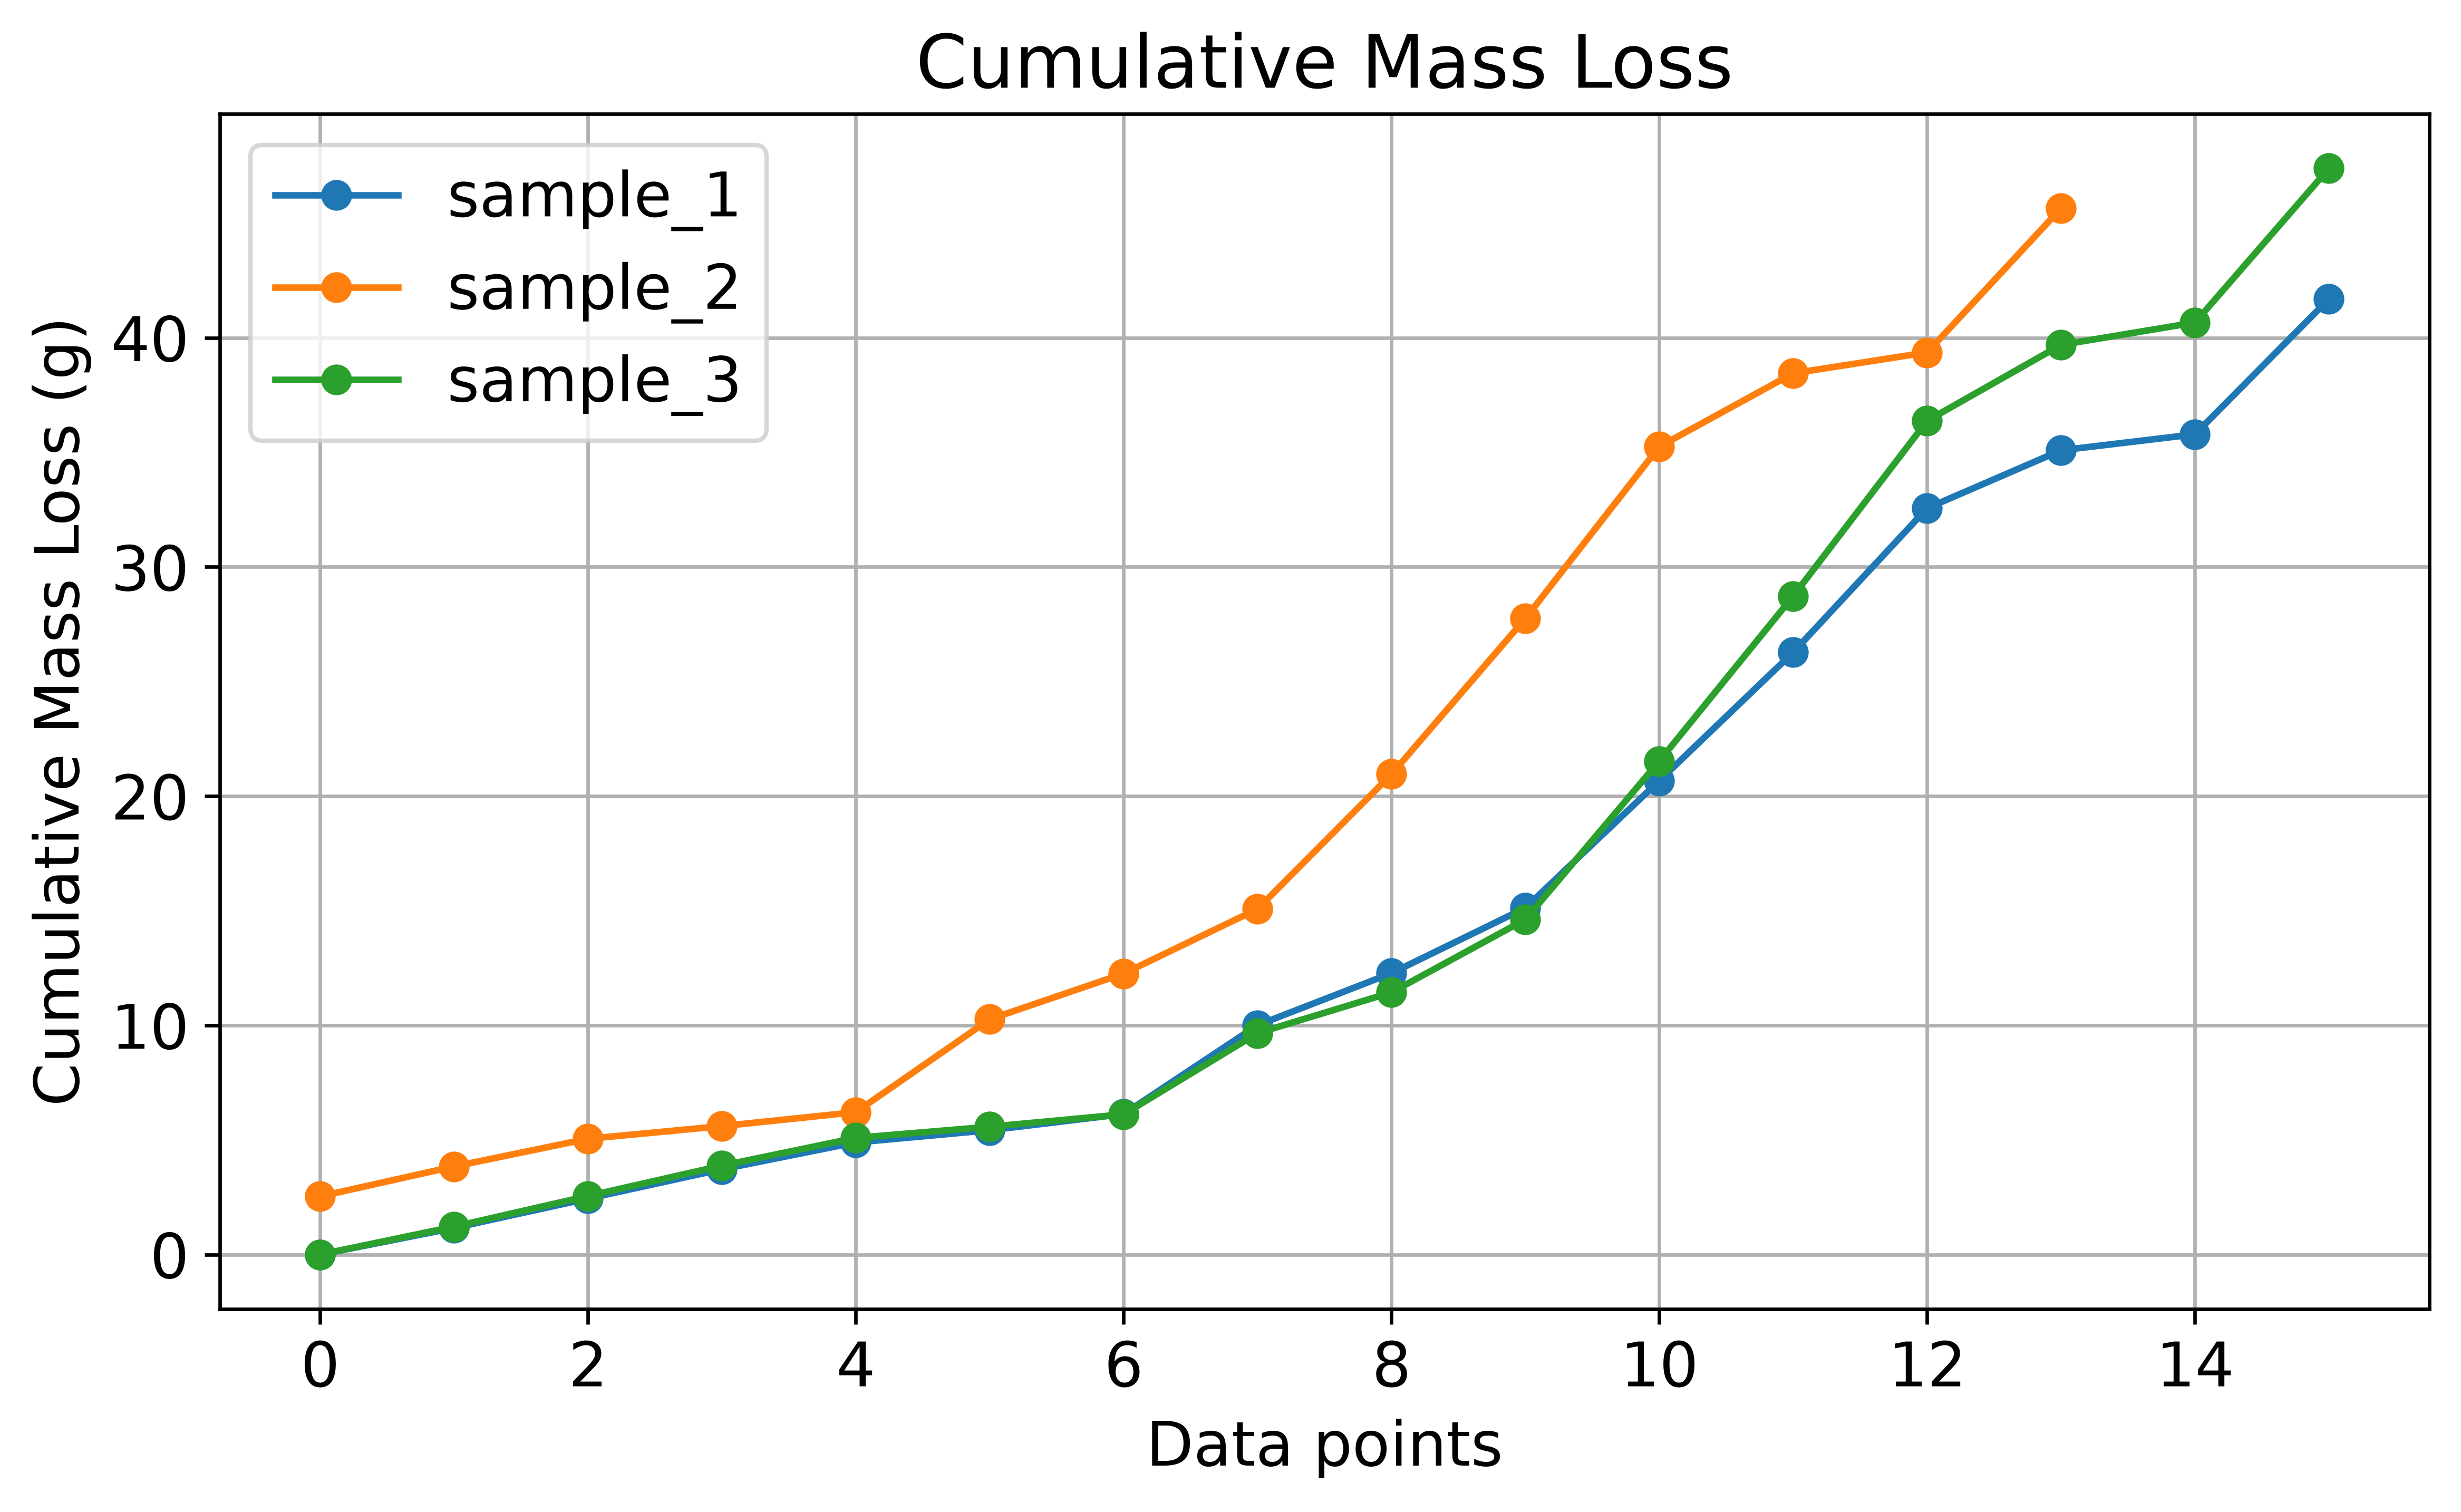

In [9]:
# Load dataset
df = merged_df_eng.copy()

# Convert timestamp to datetime (optional)
df["timestamp"] = pd.to_datetime(df["timestamp"])

# Samples to plot
samples = ["sample_0", "sample_5", "sample_10"]

plt.figure(figsize=(8, 5))

for sample in samples:
    df_sample = df[df["sample"] == sample]
    plt.plot(
        df_sample["Cumulative_Mass_Loss_g_piecewise_cal"].values,
        marker="o"
    )

plt.xlabel("Data points")
plt.ylabel("Cumulative Mass Loss (g)")
plt.title("Cumulative Mass Loss")
plt.grid(True)
plt.legend(["sample_1", "sample_2", "sample_3"])

plt.tight_layout()
plt.show()

# 8. CNN Model Architecture

CNN1D: sliding-window 1-D conv net → Global Avg Pool → FC head → Softplus output.
make_sequences() builds overlapping windows within each sample, never crossing
sample boundaries to prevent temporal leakage.

Input  : (batch, window_size, n_features)
Output : (batch, 1)  — non-negative via Softplus


In [10]:
class CNN1D(nn.Module):
    """
    1-D Convolutional Neural Network for corrosion mass-loss regression.

    Input  : (batch, window_size, n_features)
    Output : (batch, 1)  — non-negative via Softplus

    Architecture
    ------------
    Conv1D × n_conv_layers  (channels double each layer, capped at 256)
        → Norm ('batch' | 'group' | 'none') → ReLU → Dropout
    → Global Average Pooling
    → FC(in_ch → fc_dim) → ReLU
    → FC(fc_dim → 1) → Softplus
    """

    def __init__(self, n_features: int, window_size: int,
                 n_filters: int = 32, kernel_size: int = 3,
                 n_conv_layers: int = 2, dropout: float = 0.0,
                 norm: str = 'batch'):
        super().__init__()
        conv_blocks = []
        in_ch = n_features
        for i in range(n_conv_layers):
            out_ch  = min(n_filters * (2 ** i), 256)
            padding = kernel_size // 2          # 'same' padding
            if norm == 'batch':   norm_layer = nn.BatchNorm1d(out_ch)
            elif norm == 'group': norm_layer = nn.GroupNorm(1, out_ch)
            elif norm == 'none':  norm_layer = nn.Identity()
            else: raise ValueError(f"Unknown norm: {norm}")
            conv_blocks += [
                nn.Conv1d(in_ch, out_ch, kernel_size, padding=padding),
                norm_layer,
                nn.ReLU(),
                nn.Dropout(dropout),
            ]
            in_ch = out_ch
        self.conv = nn.Sequential(*conv_blocks)
        self.gap  = nn.AdaptiveAvgPool1d(1)     # → (batch, in_ch, 1)
        fc_dim    = max(in_ch // 2, 8)
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_ch, fc_dim),
            nn.ReLU(),
            nn.Linear(fc_dim, 1),
            nn.Softplus()
        )
        self._window_size = window_size

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x : (batch, window_size, n_features) → (batch, n_features, window_size)
        x = x.permute(0, 2, 1).contiguous()
        x = self.conv(x)
        x = self.gap(x)
        return self.head(x)


def make_sequences(df: pd.DataFrame,
                   feature_cols: list,
                   target_col: str,
                   window_size: int,
                   sample_col: str = 'sample'):
    """
    Build overlapping sliding-window sequences within each sample.

    Sequences never cross sample boundaries, preventing temporal leakage.

    Parameters
    ----------
    df           : DataFrame with columns [sample_col, 'timestamp',
                   *feature_cols, target_col].  Features should already be
                   scaled before calling this function.
    feature_cols : list of feature column names
    target_col   : regression target column
    window_size  : number of consecutive time steps per window
    sample_col   : column identifying individual physical samples

    Returns
    -------
    X : np.ndarray  (N, window_size, n_features)
    y : np.ndarray  (N,)
    """
    X_parts, y_parts = [], []
    for key in df[sample_col].unique():
        sub = (df[df[sample_col] == key]
               .sort_values('timestamp')
               .reset_index(drop=True))
        Xs = sub[feature_cols].values.astype(np.float32)
        ys = sub[target_col].values.astype(np.float32)
        n  = len(sub)
        if n <= window_size:
            continue
        for i in range(window_size, n):
            X_parts.append(Xs[i - window_size: i])
            y_parts.append(ys[i])
    if not X_parts:
        return (np.empty((0, window_size, len(feature_cols)), dtype=np.float32),
                np.empty(0, dtype=np.float32))
    return (np.stack(X_parts).astype(np.float32),
            np.array(y_parts, dtype=np.float32))



# 9. Training Configuration

FEATURE_COLS              — BVD-derived model inputs
TRAIN_SAMPLES/VAL_SAMPLES — LOO split (one sample held out per fold)

In [11]:
# rel_C1 is left out: it only adds noise in leave-one-probe-out validation.
FEATURE_COLS = [
    'rel_R0',
    'rel_R1',
    'rel_L1',
    'rel_C0'
]

TARGET_COL = 'Cumulative_Mass_Loss_g_piecewise_cal'

from sklearn.preprocessing import (
    StandardScaler, QuantileTransformer,
    PowerTransformer, FunctionTransformer,
)

def make_scaler(name: str):
    """Return a scaler by name: 'standard', 'quantile', 'power', or 'none'."""
    if name == 'standard': return StandardScaler()
    if name == 'quantile': return QuantileTransformer(output_distribution='normal')
    if name == 'power':    return PowerTransformer(method='yeo-johnson')
    if name == 'none':     return FunctionTransformer(func=None)
    raise ValueError(f"Unknown scaler: {name}")




# 10. Configuration choices

The final configuration is `TRAIN_CFG` in section 11. It was chosen by leave-one-probe-out on
real held-out rows (not the interpolated ones), so the reported errors are best-case,
validation-selected numbers, not an independent test. The ablation cell at the end of
section 11 shows what each choice contributes.

Section 6 augmentation is only used for the preview and baseline cells; training augments
inside each fold (training probes only).



# 11. LOO Training

In [12]:
# ── Fold-wise pipeline: augmentation on training probes only, scoring on real held-out rows only ──
import time
from scipy.interpolate import PchipInterpolator, CubicSpline

PARAMS      = ['R0', 'C0', 'R1', 'L1', 'C1']
ALL_SAMPLES = ['sample_0', 'sample_5', 'sample_10']

def make_real(df, hampel_k=None):
    """Baseline-relative features per probe; optional Hampel spike replacement."""
    d = df.sort_values(['sample', 'timestamp']).reset_index(drop=True).copy()
    for c in PARAMS:
        d[f'{c}_0'] = d.groupby('sample')[c].transform('first')
        d[f'rel_{c}'] = (d[c] - d[f'{c}_0']) / (d[f'{c}_0'].abs() + 1e-30)
    if hampel_k:
        for c in PARAMS:
            col = f'rel_{c}'
            for s, idx in d.groupby('sample').groups.items():
                x = d.loc[idx, col]
                med = x.rolling(5, center=True, min_periods=3).median()
                mad = (x - med).abs().rolling(5, center=True, min_periods=3).median() + 1e-12
                d.loc[idx, col] = np.where((x - med).abs() > hampel_k * 1.4826 * mad, med, x)
    return d

def augment_probe(sub, cols, n_interp, noise_std=None, kind='pchip', rng=None):
    """Interpolate between real rows (PCHIP: no overshoot); noise only if noise_std is given."""
    sub = sub.sort_values('time_days'); t = sub['time_days'].values
    out = sub[['sample', 'time_days', TARGET_COL] + cols].copy(); out['is_real'] = True
    if n_interp > 0 and len(sub) > 1:
        ts = np.concatenate([np.linspace(t[i], t[i + 1], n_interp + 2)[1:-1] for i in range(len(t) - 1)])
        syn = {'sample': sub['sample'].iloc[0], 'time_days': ts, 'is_real': False}
        for c in cols:
            f = (PchipInterpolator if kind == 'pchip' else CubicSpline)(t, sub[c].values.astype(float))
            syn[c] = f(ts)
            if noise_std is not None:
                syn[c] = syn[c] + rng.normal(0, noise_std[c], len(ts))
        syn[TARGET_COL] = PchipInterpolator(t, np.maximum.accumulate(sub[TARGET_COL].values.astype(float)))(ts)
        out = pd.concat([out, pd.DataFrame(syn)], ignore_index=True)
    return out.sort_values('time_days').reset_index(drop=True)

def seqs(frame, cols, w):
    """Windows within each probe; also returns whether the terminal row is a real measurement."""
    X, y, real = [], [], []
    for s, sub in frame.groupby('sample'):
        sub = sub.sort_values('time_days'); A = sub[cols].values.astype(np.float32)
        Y = sub[TARGET_COL].values.astype(np.float32); R = sub['is_real'].values
        for i in range(w, len(sub)):
            X.append(A[i - w:i]); y.append(Y[i]); real.append(R[i])
    return np.stack(X), np.array(y, np.float32), np.array(real)

CFG_DEFAULT = dict(feats=None, scaler='power', window=1, n_interp=20, interp='pchip', noise=0.15,
                   n_filters=16, kernel=5, layers=2, dropout=0.3, norm='none', lr=5e-3, wd=1e-2,
                   epochs=300, eval_every=5, loss='mse', hampel=None)

def run_fold(val_s, cfg, seeds=(0,)):
    c = {**CFG_DEFAULT, **cfg}
    feats = c['feats'] or FEATURE_COLS
    base  = make_real(merged_df, c['hampel'])
    tr_s  = [s for s in ALL_SAMPLES if s != val_s]
    trd   = base[base['sample'].isin(tr_s)]
    std   = {k: trd[k].std() * c['noise'] for k in feats}
    rng   = np.random.default_rng(0)
    trf = pd.concat([augment_probe(trd[trd['sample'] == s], feats, c['n_interp'], std, c['interp'], rng) for s in tr_s])
    vaf = augment_probe(base[base['sample'] == val_s], feats, c['n_interp'], None, c['interp'])
    sc  = make_scaler(best_scaler_type if c['scaler'] is None else c['scaler']).fit(trd[feats].values.astype(float))
    for fr in (trf, vaf):
        fr[feats] = sc.transform(fr[feats].values.astype(float))
    Xtr, ytr, rtr = seqs(trf, feats, c['window']); Xvl, yvl, rv = seqs(vaf, feats, c['window'])
    Xv, yv = torch.from_numpy(Xvl[rv]), yvl[rv]                     # real held-out rows only
    ys = float(ytr.std()); Xt = torch.from_numpy(Xtr); yt = torch.tensor(ytr / ys).unsqueeze(1)

    models, tr_preds, vl_preds, tr_curves, vl_curves = [], [], [], [], []
    epochs_log = []
    for sd in seeds:
        torch.manual_seed(sd)
        m = CNN1D(len(feats), c['window'], c['n_filters'], c['kernel'], c['layers'], c['dropout'], c['norm'])
        opt = optim.AdamW(m.parameters(), lr=c['lr'], weight_decay=c['wd'])
        sch = optim.lr_scheduler.CosineAnnealingLR(opt, c['epochs'], eta_min=c['lr'] * 1e-3)
        crit = nn.HuberLoss() if c['loss'] == 'huber' else nn.MSELoss()
        trc, vlc, epochs_log = [], [], []
        for ep in range(1, c['epochs'] + 1):
            m.train(); opt.zero_grad()
            crit(m(Xt), yt).backward(); nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step(); sch.step()
            if ep % c['eval_every'] == 0 or ep == c['epochs']:
                m.eval()
                with torch.no_grad():
                    trc.append(float(np.mean((m(Xt).numpy().flatten() * ys - ytr) ** 2)))
                    vlc.append(float(np.mean((m(Xv).numpy().flatten() * ys - yv) ** 2)))
                epochs_log.append(ep)
        m.eval()
        with torch.no_grad():
            tr_preds.append(m(Xt).numpy().flatten() * ys); vl_preds.append(m(Xv).numpy().flatten() * ys)
        models.append(m); tr_curves.append(trc); vl_curves.append(vlc)
    tr_pred, vl_pred = np.mean(tr_preds, 0), np.mean(vl_preds, 0)
    tr_c, vl_c = np.mean(tr_curves, 0), np.mean(vl_curves, 0)       # mean over seeds, g²
    return dict(val_sample=val_s, train_samps=tr_s, model=models[0], models=models, scaler=sc, feats=feats,
                window_size=c['window'], vl_preds_seed=vl_preds, y_train=ytr, y_val=yv, y_tr_pred=tr_pred, y_vl_pred=vl_pred,
                train_is_aug=~rtr, mae=float(np.mean(np.abs(vl_pred - yv))),
                history={'epoch': epochs_log, 'train_all': list(tr_c), 'val_all': list(vl_c)},
                best_epoch=epochs_log[int(np.argmin(vl_c))], best_val_mse=float(vl_c.min()))

def run_loo(cfg, seeds=(0,)):
    """Leave-one-probe-out: RMSE (g) on real held-out rows; final epoch (ensemble) and oracle best epoch."""
    res = {s: run_fold(s, cfg, seeds) for s in ALL_SAMPLES}
    fin  = {s: float(np.sqrt(np.mean((r['y_vl_pred'] - r['y_val']) ** 2))) for s, r in res.items()}
    best = {s: float(np.sqrt(r['best_val_mse'])) for s, r in res.items()}
    return np.mean(list(fin.values())), np.mean(list(best.values())), fin

def show(name, cfg, seeds=(0, 1, 2)):
    t0 = time.time(); f, b, r = run_loo(cfg, seeds)
    print(f"{name:<34} final={f:5.2f}  oracle-best-epoch={b:5.2f}   " +
          "  ".join(f"{k.split('_')[1]}={v:5.2f}" for k, v in r.items()) + f"   ({time.time()-t0:.0f}s)")


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error as _mse

# ── BVD arm: final configuration (chosen with leave-one-probe-out on real held-out rows) ──
TRAIN_CFG = dict(
    feats      = FEATURE_COLS,
    scaler     = 'power',    # fit on training probes only
    window     = 1,          # window>1 only spans fractions of a real interval after interpolation
    n_interp   = 20,         # PCHIP points between consecutive real rows (training probes only)
    noise      = 0.15,       # Gaussian noise on synthetic training rows, fraction of feature std
    n_filters  = 16, kernel = 5, layers = 2,
    dropout    = 0.3,
    norm       = 'none',     # GroupNorm/BatchNorm erase absolute feature level at window=1
    lr         = 5e-3, wd = 1e-2,          # AdamW + cosine decay
    epochs     = 300,        # fixed: no checkpoint picked on the held-out probe
    eval_every = 1,
)
SEEDS = (0, 1, 2, 3, 4)      # predictions are the mean of these seeds (same for the raw arm)

def run_arm(fold_fn, cfg, label):
    """Run all three leave-one-probe-out folds for one arm and print a summary."""
    out = []
    for fold_idx, val_samp in enumerate(ALL_SAMPLES):
        t0 = time.time()
        r = fold_fn(val_samp, cfg, SEEDS)
        h = r['history']
        r['selected_epoch']   = h['epoch'][-1]
        r['selected_val_mse'] = h['val_all'][-1]
        print(f"[{label}] FOLD {fold_idx+1}/3  val={val_samp}  train rows={len(r['y_train'])} "
              f"(real {int((~r['train_is_aug']).sum())})  val real rows={len(r['y_val'])}  "
              f"final val MSE {r['selected_val_mse']:.2f} g²  MAE {r['mae']:.3f} g  [{time.time()-t0:.0f}s]")
        out.append(r)
    print(f"[{label}] mean val RMSE {np.mean([np.sqrt(_mse(r['y_val'], r['y_vl_pred'])) for r in out]):.3f} g\n")
    return out

bvd_results = run_arm(run_fold, TRAIN_CFG, 'BVD')


KeyboardInterrupt: 

# 11b. Raw impedance arm

Same 46 (probe, timestamp) rows, same leave-one-probe-out folds, same CNN, same augmentation
(PCHIP between measurements, training probes only), same seeds and scoring (real held-out rows,
fixed epochs). The only change is the input: the full 50-350 kHz spectrum per measurement
instead of four BVD parameters.

The spectrum is read with the same scaling as `bvd_utils` (|Z| x 1e5, phase x -100), so both
arms see the same complex impedance. The frequency axis plays the role of the CNN "window".


In [ ]:
# ── Raw spectra for the same rows as the BVD arm ────────────────────────────────────────
CORR_DIR = "Corrosion_Dataset"
_folders = {f[:19]: f for f in os.listdir(CORR_DIR) if re.match(r'^\d{4}-\d{2}-\d{2}_\d{2}-\d{2}-\d{2}_', f)}

raw_rows = (merged_df.sort_values(['sample', 'timestamp']).reset_index(drop=True)
            [['sample', 'timestamp', 'time_days', TARGET_COL]])
_mag, _ph = [], []
for s, ts in zip(raw_rows['sample'], raw_rows['timestamp']):
    _x = pd.read_csv(os.path.join(CORR_DIR, _folders[ts.strftime('%Y-%m-%d_%H-%M-%S')], f'{s}.csv'))
    _mag.append(_x['Impedance (ohms)'].values * 10e4)   # same scaling as bvd_utils
    _ph.append(_x['Phase (Radians)'].values * -100)
FREQ = _x['Frequency (Hz)'].values
MAG, PH = np.stack(_mag), np.stack(_ph)                 # (rows, freq)
_first = raw_rows.groupby('sample').head(1).index
I0 = raw_rows['sample'].map(dict(zip(raw_rows.loc[_first, 'sample'], _first))).values   # baseline row per probe
print(f"{len(raw_rows)} spectra, {MAG.shape[1]} frequency points, "
      f"{FREQ[0]/1e3:.0f}-{FREQ[-1]/1e3:.0f} kHz")


def raw_tensor(rep, bins, band=None):
    """(rows, freq_bins, channels). Baseline-relative reps use each probe's first row, like rel_* in the BVD arm."""
    Z = MAG * np.exp(1j * PH)
    if rep == 'rel':    ch = [np.log(MAG / MAG[I0]), PH - PH[I0]]
    elif rep == 'abs':  ch = [np.log(MAG), PH]
    elif rep == 'reim': ch = [Z.real - Z.real[I0], Z.imag - Z.imag[I0]]
    else: raise ValueError(rep)
    X = np.stack(ch, -1)
    if band is not None:
        X = X[:, (FREQ >= band[0]) & (FREQ <= band[1])]
    if bins > 1:
        n = X.shape[1] // bins * bins
        X = X[:, :n].reshape(len(X), -1, bins, X.shape[-1]).mean(2)
    return X.astype(np.float32)


def augment_raw(Xp, t, y, n_interp, noise_sd=None, rng=None):
    """PCHIP between consecutive spectra of one probe; noise only if noise_sd is given."""
    n = len(t)
    ts = np.concatenate([np.linspace(t[i], t[i + 1], n_interp + 2)[1:-1] for i in range(n - 1)])
    syn = PchipInterpolator(t, Xp.reshape(n, -1), axis=0)(ts).reshape(len(ts), *Xp.shape[1:])
    if noise_sd is not None:
        syn = syn + rng.normal(0, 1, syn.shape) * noise_sd
    ys = PchipInterpolator(t, np.maximum.accumulate(y))(ts)
    tt = np.concatenate([t, ts]); o = np.argsort(tt)
    X = np.concatenate([Xp, syn])[o]; yy = np.concatenate([y, ys])[o]
    real = np.concatenate([np.ones(n, bool), np.zeros(len(ts), bool)])[o]
    return X, yy, real


def seqs_raw(X, y, real):
    """Same convention as seqs(window=1): features of stream element i-1 predict y[i]."""
    return X[:-1], y[1:], real[1:]


def train_ensemble(Xtr, ytr, Xv, yv, n_feat, window, c, seeds):
    """Fixed-epoch training of len(seeds) CNN1D models; returns mean predictions and mean MSE curves (g²)."""
    ys = float(ytr.std()); Xt = torch.from_numpy(Xtr); yt = torch.tensor(ytr / ys).unsqueeze(1); Xvt = torch.from_numpy(Xv)
    models, trp, vlp, trcs, vlcs = [], [], [], [], []
    for sd in seeds:
        torch.manual_seed(sd)
        m = CNN1D(n_feat, window, c['n_filters'], c['kernel'], c['layers'], c['dropout'], c['norm'])
        opt = optim.AdamW(m.parameters(), lr=c['lr'], weight_decay=c['wd'])
        sch = optim.lr_scheduler.CosineAnnealingLR(opt, c['epochs'], eta_min=c['lr'] * 1e-3)
        crit = nn.MSELoss(); trc, vlc, eps = [], [], []
        for ep in range(1, c['epochs'] + 1):
            m.train(); opt.zero_grad()
            crit(m(Xt), yt).backward(); nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step(); sch.step()
            if ep % c['eval_every'] == 0 or ep == c['epochs']:
                m.eval()
                with torch.no_grad():
                    trc.append(float(np.mean((m(Xt).numpy().flatten() * ys - ytr) ** 2)))
                    vlc.append(float(np.mean((m(Xvt).numpy().flatten() * ys - yv) ** 2)))
                eps.append(ep)
        m.eval()
        with torch.no_grad():
            trp.append(m(Xt).numpy().flatten() * ys); vlp.append(m(Xvt).numpy().flatten() * ys)
        models.append(m); trcs.append(trc); vlcs.append(vlc)
    return models, np.mean(trp, 0), np.mean(vlp, 0), np.mean(trcs, 0), np.mean(vlcs, 0), eps, vlp


RAW_DEFAULT = dict(rep='rel', bins=30, band=None, scaler='channel', coord=False, n_interp=10, noise=0.15,
                   n_filters=16, kernel=5, layers=2, dropout=0.3, norm='none', lr=5e-3, wd=1e-2,
                   epochs=200, eval_every=20)

def run_fold_raw(val_s, cfg, seeds=(0,)):
    c = {**RAW_DEFAULT, **cfg}
    T = raw_tensor(c['rep'], c['bins'], c['band'])
    t = raw_rows['time_days'].values; y = raw_rows[TARGET_COL].values.astype(float); smp = raw_rows['sample'].values
    tr_s = [s for s in ALL_SAMPLES if s != val_s]
    Tr = T[np.isin(smp, tr_s)]                                     # real training rows only
    if c['scaler'] == 'freq':
        mu, sd = Tr.mean(0), Tr.std(0); sd = np.maximum(sd, 0.1 * sd.mean(0, keepdims=True))
    elif c['scaler'] == 'channel':
        mu, sd = Tr.mean((0, 1), keepdims=True)[0], Tr.std((0, 1), keepdims=True)[0]
    else:
        mu, sd = 0.0, 1.0
    noise_sd = c['noise'] * Tr.std(0)                              # per (freq, channel), raw scale
    rng = np.random.default_rng(0)
    parts = []
    for s in tr_s:
        m = smp == s; parts.append(seqs_raw(*augment_raw(T[m], t[m], y[m], c['n_interp'], noise_sd, rng)))
    Xtr = np.concatenate([p[0] for p in parts]); ytr = np.concatenate([p[1] for p in parts]); rtr = np.concatenate([p[2] for p in parts])
    m = smp == val_s
    Xva, yva, rva = seqs_raw(*augment_raw(T[m], t[m], y[m], c['n_interp']))
    Xtr, Xva = (Xtr - mu) / sd, (Xva - mu) / sd
    if c['coord']:                                                 # lets the conv see where on the frequency axis it is
        pos = np.linspace(-1, 1, Xtr.shape[1], dtype=np.float32)[None, :, None]
        Xtr = np.concatenate([Xtr, np.broadcast_to(pos, (len(Xtr), Xtr.shape[1], 1))], -1)
        Xva = np.concatenate([Xva, np.broadcast_to(pos, (len(Xva), Xva.shape[1], 1))], -1)
    Xtr, Xva = Xtr.astype(np.float32), Xva[rva].astype(np.float32)  # validate on real held-out rows only
    yv = yva[rva].astype(np.float32); ytr = ytr.astype(np.float32)
    models, tr_pred, vl_pred, tr_c, vl_c, eps, vl_seed = train_ensemble(Xtr, ytr, Xva, yv, Xtr.shape[-1], Xtr.shape[1], c, seeds)
    return dict(val_sample=val_s, train_samps=tr_s, model=models[0], models=models, scaler=None, feats=None,
                window_size=Xtr.shape[1], vl_preds_seed=vl_seed, y_train=ytr, y_val=yv, y_tr_pred=tr_pred, y_vl_pred=vl_pred,
                train_is_aug=~rtr, mae=float(np.mean(np.abs(vl_pred - yv))),
                history={'epoch': eps, 'train_all': list(tr_c), 'val_all': list(vl_c)},
                best_epoch=eps[int(np.argmin(vl_c))], best_val_mse=float(vl_c.min()))

def show_raw(name, cfg, seeds=(0, 1, 2)):
    t0 = time.time(); res = {s: run_fold_raw(s, cfg, seeds) for s in ALL_SAMPLES}
    fin = {s: float(np.sqrt(np.mean((r['y_vl_pred'] - r['y_val']) ** 2))) for s, r in res.items()}
    best = np.mean([np.sqrt(r['best_val_mse']) for r in res.values()])
    print(f"{name:<34} final={np.mean(list(fin.values())):5.2f}  oracle-best-epoch={best:5.2f}   " +
          "  ".join(f"{k.split('_')[1]}={v:5.2f}" for k, v in fin.items()) + f"   ({time.time()-t0:.0f}s)")
    return np.mean(list(fin.values()))


46 spectra, 3000 frequency points, 50-350 kHz


In [ ]:
# Raw-arm variants that were tried (2-seed ensembles, held-out RMSE in g on real rows).
# The comparison does not need the best raw setup; this sweep only shows the raw result is not one unlucky choice.
# Resumable: re-run the cell until every variant is done (about 45 s per variant); results go to the figures folder.
OUT_DIR = "Figures/BVD_vs_Raw"; os.makedirs(OUT_DIR, exist_ok=True)

RAW_SWEEP_CFGS = {
    'rel, norm none':            dict(norm='none'),
    'rel, + coord channel':      dict(norm='none', coord=True),
    'rel, per-freq scale':       dict(norm='none', scaler='freq'),
    'abs (no baseline)':         dict(norm='none', rep='abs'),
    'reim (rel. to base)':       dict(norm='none', rep='reim'),
    'rel, norm group':           dict(norm='group'),
    'group + dropout .5':        dict(norm='group', dropout=0.5),
    'group, noise .3':           dict(norm='group', noise=0.3),
    'group, noise .6':           dict(norm='group', noise=0.6),
    'group, layers 1':           dict(norm='group', layers=1),
    'group, band 150-260k':      dict(norm='group', band=(150e3, 260e3), bins=15),
    'group, band 180-240k':      dict(norm='group', band=(180e3, 240e3), bins=10),
    'norm batch':                dict(norm='batch'),
}
RUN_RAW_SWEEP, MAX_PER_RUN = False, 7
raw_sweep = globals().get('raw_sweep', {})
if RUN_RAW_SWEEP:
    done = 0
    for name, cfg in RAW_SWEEP_CFGS.items():
        if name in raw_sweep or done >= MAX_PER_RUN:
            continue
        t0 = time.time(); res = {s: run_fold_raw(s, cfg, (0, 1)) for s in ALL_SAMPLES}
        raw_sweep[name] = {s: float(np.sqrt(np.mean((r['y_vl_pred'] - r['y_val']) ** 2))) for s, r in res.items()}
        print(f"{name:<24} mean RMSE {np.mean(list(raw_sweep[name].values())):6.2f}   ({time.time()-t0:.0f}s)")
        done += 1
    if len(raw_sweep) == len(RAW_SWEEP_CFGS):
        pd.DataFrame(raw_sweep).T.to_csv(f"{OUT_DIR}/raw_sweep.csv")


group, noise .3          mean RMSE  15.75   (57s)
group, noise .6          mean RMSE  17.48   (58s)
group, layers 1          mean RMSE  15.23   (20s)
group, band 150-260k     mean RMSE  13.37   (40s)
group, band 180-240k     mean RMSE  13.79   (35s)
norm batch               mean RMSE  14.53   (60s)


In [ ]:
# ── Raw arm: fixed, lightly tuned configuration (full 50-350 kHz band, 30-point block means) ──
RAW_CFG = dict(rep='rel', bins=30, band=None, scaler='channel', coord=False, n_interp=10, noise=0.15,
               n_filters=16, kernel=5, layers=2, dropout=0.3, norm='group', lr=5e-3, wd=1e-2,
               epochs=200, eval_every=1)
raw_results = run_arm(run_fold_raw, RAW_CFG, 'RAW')

# Section 12 and the curve plot below show the raw arm; BVD results stay in bvd_results.
fold_results = raw_results
model = raw_results[-1]['model']


[RAW] FOLD 1/3  val=sample_0  train rows=308 (real 28)  val real rows=15  final val MSE 323.36 g²  MAE 14.555 g  [49s]
[RAW] FOLD 2/3  val=sample_5  train rows=330 (real 30)  val real rows=13  final val MSE 426.80 g²  MAE 16.611 g  [49s]
[RAW] FOLD 3/3  val=sample_10  train rows=308 (real 28)  val real rows=15  final val MSE 76.55 g²  MAE 6.637 g  [42s]
[RAW] mean val RMSE 15.386 g



In [ ]:
# ── BVD vs raw impedance: metrics on identical folds/rows/seeds/scoring ──────────────────
from sklearn.metrics import r2_score as _r2

OUT_DIR = "Figures/BVD_vs_Raw"; os.makedirs(OUT_DIR, exist_ok=True)
ARM_COLOR = {'train mean': 'lightgray', 'raw impedance': 'tab:orange', 'BVD features': 'tab:blue'}
MODELS = ['train mean', 'raw impedance', 'BVD features']
_rm = lambda p, y: float(np.sqrt(np.mean((np.asarray(p) - np.asarray(y)) ** 2)))
_np = lambda m: sum(p.numel() for p in m.parameters())

rows = []
for s in ALL_SAMPLES:
    rb = next(r for r in bvd_results if r['val_sample'] == s)
    rr = next(r for r in raw_results if r['val_sample'] == s)
    assert np.allclose(rb['y_val'], rr['y_val']), "arms are scored on different rows"
    y = rb['y_val']
    mp = np.full_like(y, raw_rows.loc[raw_rows['sample'] != s, TARGET_COL].mean())
    rows.append(dict(probe=s, model='train mean', rmse=_rm(mp, y), mae=float(np.mean(np.abs(mp - y))), r2=_r2(y, mp),
                     seed_std=0.0, train_rmse=np.nan, oracle_rmse=np.nan, n_inputs=0, n_params=0))
    for arm, r in [('BVD features', rb), ('raw impedance', rr)]:
        mr = ~r['train_is_aug']
        rows.append(dict(probe=s, model=arm, rmse=_rm(r['y_vl_pred'], y), mae=float(np.mean(np.abs(r['y_vl_pred'] - y))),
                         r2=_r2(y, r['y_vl_pred']), seed_std=float(np.std([_rm(p, y) for p in r['vl_preds_seed']])),
                         train_rmse=_rm(r['y_tr_pred'][mr], r['y_train'][mr]), oracle_rmse=float(np.sqrt(r['best_val_mse'])),
                         n_inputs=r['model'].conv[0].in_channels * r['window_size'], n_params=_np(r['model'])))
per_probe = pd.DataFrame(rows)
per_probe['gap'] = per_probe['rmse'] - per_probe['train_rmse']

summary = (per_probe.groupby('model')[['rmse', 'mae', 'r2', 'seed_std', 'train_rmse', 'gap', 'oracle_rmse', 'n_inputs', 'n_params']]
           .mean().loc[MODELS])
summary['wins_vs_raw'] = ['', '', f"{int((per_probe[per_probe.model=='BVD features'].rmse.values < per_probe[per_probe.model=='raw impedance'].rmse.values).sum())}/3"]

print("Per probe (RMSE g, final epoch, 5-seed ensemble, real held-out rows)")
print(per_probe.pivot(index='model', columns='probe', values='rmse')[ALL_SAMPLES].loc[MODELS].round(2).to_string())
print("\nMean over the 3 held-out probes")
print(summary.round(2).to_string())
per_probe.to_csv(f"{OUT_DIR}/metrics_per_probe.csv", index=False); summary.to_csv(f"{OUT_DIR}/metrics_summary.csv")


Per probe (RMSE g, final epoch, 5-seed ensemble, real held-out rows)
probe          sample_0  sample_5  sample_10
model                                       
train mean        13.58     15.01      15.56
raw impedance     17.34     20.13       8.69
BVD features       3.13      4.97       3.13

Mean over the 3 held-out probes
                rmse    mae    r2  seed_std  train_rmse   gap  oracle_rmse  n_inputs  n_params wins_vs_raw
model                                                                                                     
train mean     14.71  12.95 -0.03      0.00         NaN   NaN          NaN       0.0       0.0            
raw impedance  15.39  12.60 -0.30      1.71        6.98  8.41        12.07     200.0    3409.0            
BVD features    3.74   2.86  0.93      1.36        3.07  0.67         4.13       4.0    3473.0         3/3


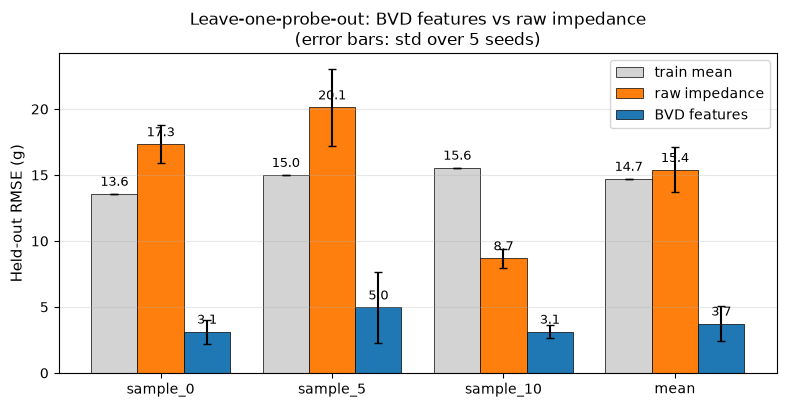

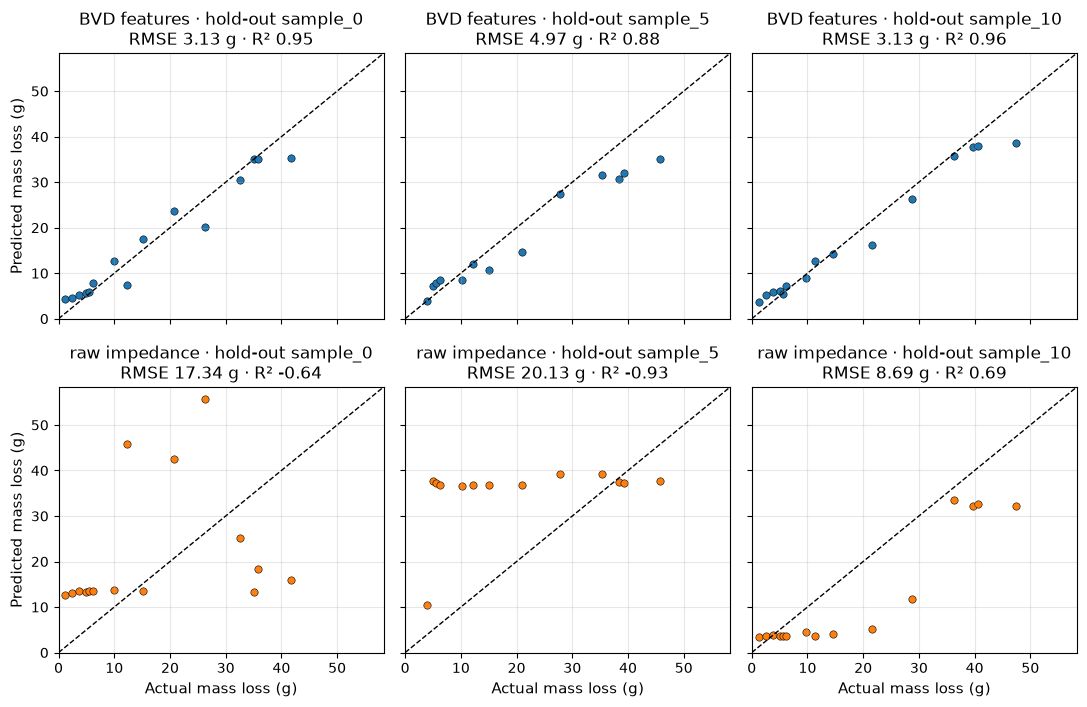

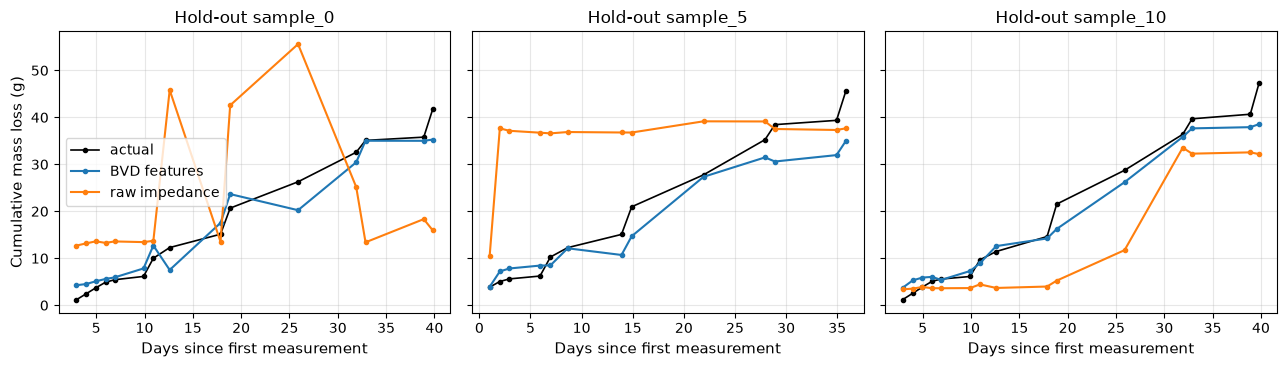

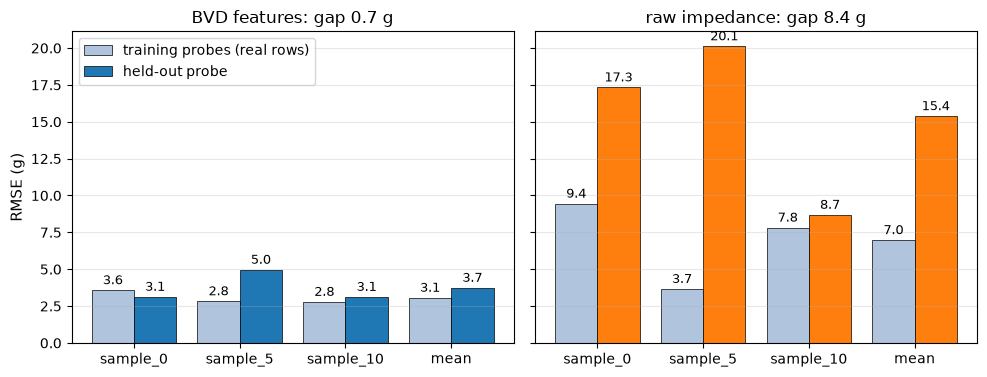

In [ ]:
# ── Figures 1-4 (saved to Figures/BVD_vs_Raw) ─────────────────────────────────────────
RC = {'font.size': 11, 'axes.titlesize': 12, 'axes.labelsize': 11, 'xtick.labelsize': 10, 'ytick.labelsize': 10,
      'legend.fontsize': 10, 'figure.dpi': 100}
PLABEL = {'sample_0': 'sample_0', 'sample_5': 'sample_5', 'sample_10': 'sample_10'}
RES = {'BVD features': bvd_results, 'raw impedance': raw_results}
_pp = lambda model, col: [per_probe[(per_probe.probe == s) & (per_probe.model == model)][col].iloc[0] for s in ALL_SAMPLES]

with plt.rc_context(RC):
    # Fig 1: per-probe held-out RMSE with seed spread
    fig, ax = plt.subplots(figsize=(8, 4.2))
    w = 0.27; x = np.arange(4)
    for k, m in enumerate(MODELS):
        vals = _pp(m, 'rmse') + [summary.loc[m, 'rmse']]
        errs = _pp(m, 'seed_std') + [summary.loc[m, 'seed_std']]
        bars = ax.bar(x + (k - 1) * w, vals, w, yerr=errs, capsize=3, label=m, color=ARM_COLOR[m], edgecolor='k', linewidth=0.5)
        for b_, v in zip(bars, vals):
            ax.text(b_.get_x() + b_.get_width() / 2, v + 0.6, f'{v:.1f}', ha='center', fontsize=9)
    ax.set_xticks(x); ax.set_xticklabels(ALL_SAMPLES + ['mean'])
    ax.set_ylabel('Held-out RMSE (g)'); ax.set_title('Leave-one-probe-out: BVD features vs raw impedance\n(error bars: std over 5 seeds)')
    ax.legend(); ax.grid(True, axis='y', alpha=0.3); plt.tight_layout()
    fig.savefig(f"{OUT_DIR}/01_rmse_per_probe.png", dpi=200); plt.show()

    # Fig 2: parity plots, BVD on top row, raw below
    lim = max(max(r['y_val'].max(), r['y_vl_pred'].max()) for res in RES.values() for r in res) * 1.05
    fig, axes = plt.subplots(2, 3, figsize=(11, 7.2), sharex=True, sharey=True)
    for i, (arm, res) in enumerate(RES.items()):
        for j, r in enumerate(res):
            ax = axes[i, j]; y, p = r['y_val'], r['y_vl_pred']
            ax.plot([0, lim], [0, lim], 'k--', lw=1)
            ax.scatter(y, p, s=28, color=ARM_COLOR[arm], edgecolors='k', linewidths=0.4)
            ax.set_title(f"{arm} · hold-out {r['val_sample']}\nRMSE {_rm(p, y):.2f} g · R² {_r2(y, p):.2f}")
            ax.set_xlim(0, lim); ax.set_ylim(0, lim); ax.grid(True, alpha=0.3)
            if i == 1: ax.set_xlabel('Actual mass loss (g)')
            if j == 0: ax.set_ylabel('Predicted mass loss (g)')
    plt.tight_layout(); fig.savefig(f"{OUT_DIR}/02_parity_bvd_vs_raw.png", dpi=200); plt.show()

    # Fig 3: predictions over the measurement period for each held-out probe
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
    for j, s in enumerate(ALL_SAMPLES):
        t = raw_rows.loc[raw_rows['sample'] == s, 'time_days'].values[1:]
        t = t - raw_rows.loc[raw_rows['sample'] == s, 'time_days'].values[0]
        rb = next(r for r in bvd_results if r['val_sample'] == s); rr = next(r for r in raw_results if r['val_sample'] == s)
        assert len(t) == len(rb['y_val'])
        ax = axes[j]
        ax.plot(t, rb['y_val'], 'k-o', ms=3, lw=1.2, label='actual')
        ax.plot(t, rb['y_vl_pred'], '-o', ms=3, color=ARM_COLOR['BVD features'], label='BVD features')
        ax.plot(t, rr['y_vl_pred'], '-o', ms=3, color=ARM_COLOR['raw impedance'], label='raw impedance')
        ax.set_title(f'Hold-out {s}'); ax.set_xlabel('Days since first measurement'); ax.grid(True, alpha=0.3)
    axes[0].set_ylabel('Cumulative mass loss (g)'); axes[0].legend()
    plt.tight_layout(); fig.savefig(f"{OUT_DIR}/03_prediction_over_time.png", dpi=200); plt.show()

    # Fig 4: generalization gap, training vs held-out error
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.9), sharey=True)
    for ax, arm in zip(axes, ['BVD features', 'raw impedance']):
        tr = _pp(arm, 'train_rmse') + [summary.loc[arm, 'train_rmse']]; ho = _pp(arm, 'rmse') + [summary.loc[arm, 'rmse']]
        x = np.arange(4)
        ax.bar(x - 0.2, tr, 0.4, label='training probes (real rows)', color='lightsteelblue', edgecolor='k', linewidth=0.5)
        ax.bar(x + 0.2, ho, 0.4, label='held-out probe', color=ARM_COLOR[arm], edgecolor='k', linewidth=0.5)
        for xi, (a, b_) in enumerate(zip(tr, ho)):
            ax.text(xi - 0.2, a + 0.4, f'{a:.1f}', ha='center', fontsize=9); ax.text(xi + 0.2, b_ + 0.4, f'{b_:.1f}', ha='center', fontsize=9)
        ax.set_xticks(x); ax.set_xticklabels(ALL_SAMPLES + ['mean']); ax.set_title(f'{arm}: gap {summary.loc[arm, "gap"]:.1f} g')
        ax.grid(True, axis='y', alpha=0.3)
    axes[0].set_ylabel('RMSE (g)'); axes[0].legend(loc='upper left')
    plt.tight_layout(); fig.savefig(f"{OUT_DIR}/04_generalization_gap.png", dpi=200); plt.show()


BVD − rel_L1 (R0,R1,C0)        mean RMSE  33.76   sample_0=47.53  sample_5=39.70  sample_10=14.04
BVD − rel_L1 (R0,R1,C0,C1)     mean RMSE  25.43   sample_0=15.54  sample_5=41.25  sample_10=19.52


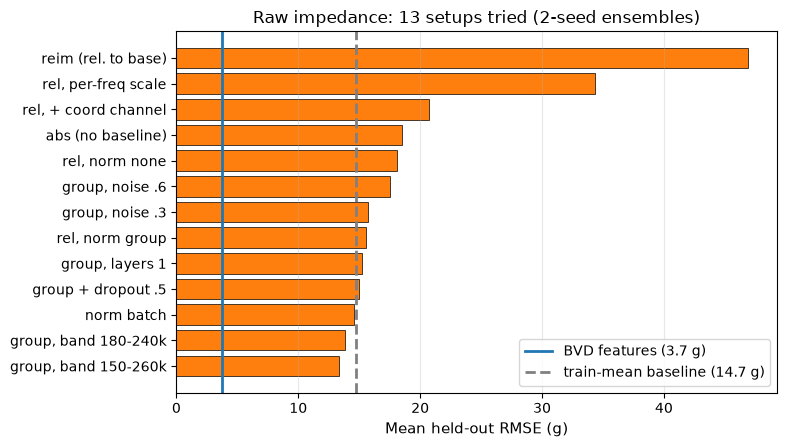

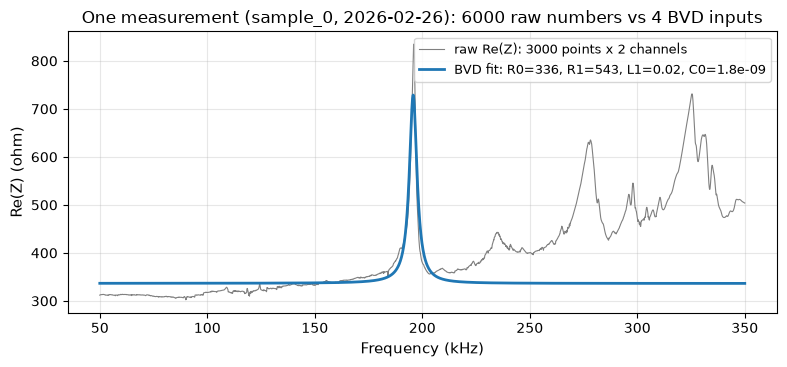

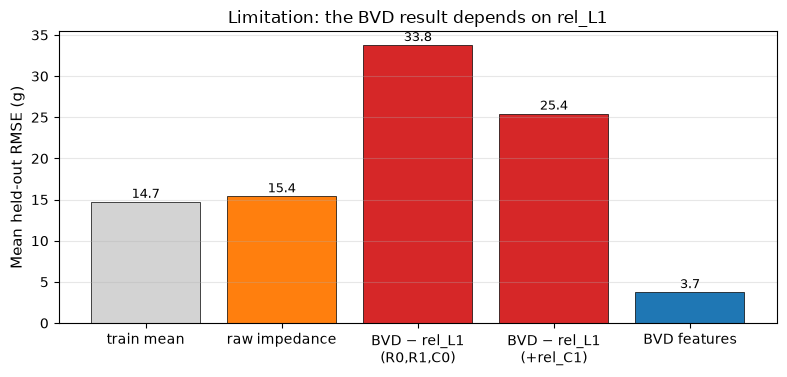

In [ ]:
# ── Figures 5-7: raw-setup sensitivity, input compression, and the rel_L1 limitation ──────
from bvd_utils import bvd_1st_order

# BVD without rel_L1 (same settings/seeds): what carries the BVD signal?
abl = {}
for name, fs in [('BVD − rel_L1 (R0,R1,C0)', ['rel_R0', 'rel_R1', 'rel_C0']),
                 ('BVD − rel_L1 (R0,R1,C0,C1)', ['rel_R0', 'rel_R1', 'rel_C0', 'rel_C1'])]:
    f_, b_, fin = run_loo({**TRAIN_CFG, 'feats': fs, 'eval_every': 20}, SEEDS)
    abl[name] = dict(**fin, mean=f_)
    print(f"{name:<30} mean RMSE {f_:6.2f}   " + "  ".join(f"{k}={v:5.2f}" for k, v in fin.items()))
pd.DataFrame(abl).T.to_csv(f"{OUT_DIR}/bvd_without_rel_L1.csv")

with plt.rc_context(RC):
    # Fig 5: raw result across the variants that were tried
    sw = pd.DataFrame(raw_sweep).T if raw_sweep else pd.read_csv(f"{OUT_DIR}/raw_sweep.csv", index_col=0)
    sw['mean'] = sw.mean(axis=1); sw = sw.sort_values('mean')
    fig, ax = plt.subplots(figsize=(8, 4.6))
    ax.barh(sw.index, sw['mean'], color=ARM_COLOR['raw impedance'], edgecolor='k', linewidth=0.5)
    ax.axvline(summary.loc['BVD features', 'rmse'], color=ARM_COLOR['BVD features'], lw=2, label=f"BVD features ({summary.loc['BVD features', 'rmse']:.1f} g)")
    ax.axvline(summary.loc['train mean', 'rmse'], color='gray', lw=2, ls='--', label=f"train-mean baseline ({summary.loc['train mean', 'rmse']:.1f} g)")
    ax.set_xlabel('Mean held-out RMSE (g)'); ax.set_title(f'Raw impedance: {len(sw)} setups tried (2-seed ensembles)')
    ax.legend(loc='lower right'); ax.grid(True, axis='x', alpha=0.3); plt.tight_layout()
    fig.savefig(f"{OUT_DIR}/05_raw_setups_tried.png", dpi=200); plt.show()

    # Fig 6: what each arm sees for one measurement
    mrow = merged_df.sort_values(['sample', 'timestamp']).reset_index(drop=True)
    i = int(np.where(mrow['sample'] == 'sample_0')[0][8]); pr = mrow.loc[i]
    Z = MAG[i] * np.exp(1j * PH[i]); Zf = bvd_1st_order(FREQ, pr['R0'], pr['C0'], pr['R1'], pr['L1'], pr['C1'])
    fig, ax = plt.subplots(figsize=(8, 3.8))
    ax.plot(FREQ / 1e3, Z.real, color='gray', lw=0.8, label=f'raw Re(Z): {len(FREQ)} points x 2 channels')
    ax.plot(FREQ / 1e3, Zf.real, color=ARM_COLOR['BVD features'], lw=2,
            label=f"BVD fit: R0={pr['R0']:.0f}, R1={pr['R1']:.0f}, L1={pr['L1']:.3g}, C0={pr['C0']:.2g}")
    ax.set_xlabel('Frequency (kHz)'); ax.set_ylabel('Re(Z) (ohm)'); ax.grid(True, alpha=0.3)
    ax.set_title(f"One measurement ({pr['sample']}, {pr['timestamp'].date()}): {2 * len(FREQ)} raw numbers vs 4 BVD inputs")
    ax.legend(loc='upper right', fontsize=9); plt.tight_layout()
    fig.savefig(f"{OUT_DIR}/06_input_compression.png", dpi=200); plt.show()

    # Fig 7: limitation, BVD result without rel_L1
    labels = ['train mean', 'raw impedance', 'BVD − rel_L1\n(R0,R1,C0)', 'BVD − rel_L1\n(+rel_C1)', 'BVD features']
    vals = [summary.loc['train mean', 'rmse'], summary.loc['raw impedance', 'rmse'],
            abl['BVD − rel_L1 (R0,R1,C0)']['mean'], abl['BVD − rel_L1 (R0,R1,C0,C1)']['mean'], summary.loc['BVD features', 'rmse']]
    cols = ['lightgray', ARM_COLOR['raw impedance'], 'tab:red', 'tab:red', ARM_COLOR['BVD features']]
    fig, ax = plt.subplots(figsize=(8, 3.9))
    bars = ax.bar(labels, vals, color=cols, edgecolor='k', linewidth=0.5)
    for b_, v in zip(bars, vals):
        ax.text(b_.get_x() + b_.get_width() / 2, v + 0.5, f'{v:.1f}', ha='center', fontsize=9)
    ax.set_ylabel('Mean held-out RMSE (g)'); ax.set_title('rel_L1 is the mass channel: BVD with and without it')
    ax.grid(True, axis='y', alpha=0.3); plt.tight_layout()
    fig.savefig(f"{OUT_DIR}/07_limitation_rel_L1.png", dpi=200); plt.show()


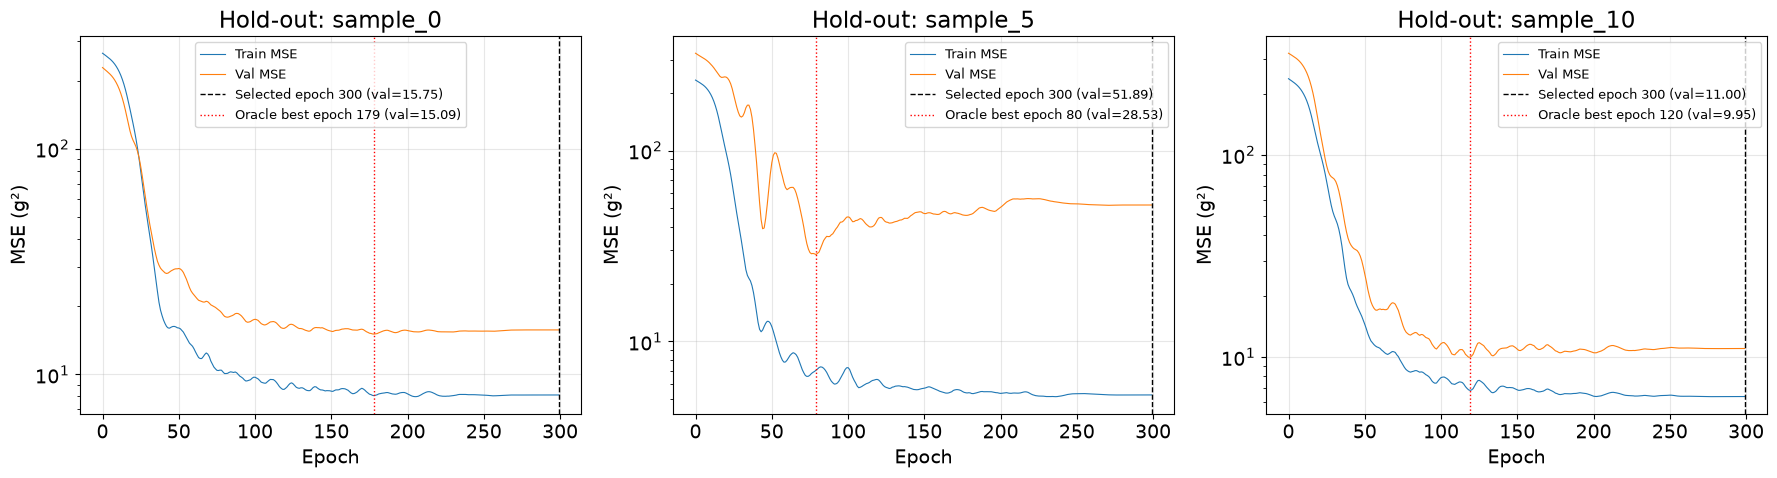

In [ ]:
# MSE vs. epoch per fold: is val settling at a minimum or is the best epoch a lucky dip?
fig, axes = plt.subplots(1, 3, figsize=(18, 5), dpi=100)
for ax, r in zip(axes, fold_results):
    h = r['history']
    ax.plot(h['train_all'], lw=0.8, label='Train MSE')
    ax.plot(h['val_all'],   lw=0.8, label='Val MSE')
    ax.axvline(r['selected_epoch'] - 1, color='k', ls='--', lw=1,
               label=f"Selected epoch {r['selected_epoch']} (val={r['selected_val_mse']:.2f})")
    ax.axvline(r['best_epoch'] - 1, color='r', ls=':', lw=1,
               label=f"Oracle best epoch {r['best_epoch']} (val={r['best_val_mse']:.2f})")
    ax.set_yscale('log')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('MSE (g²)')
    ax.set_title(f"Hold-out: {r['val_sample']}")
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


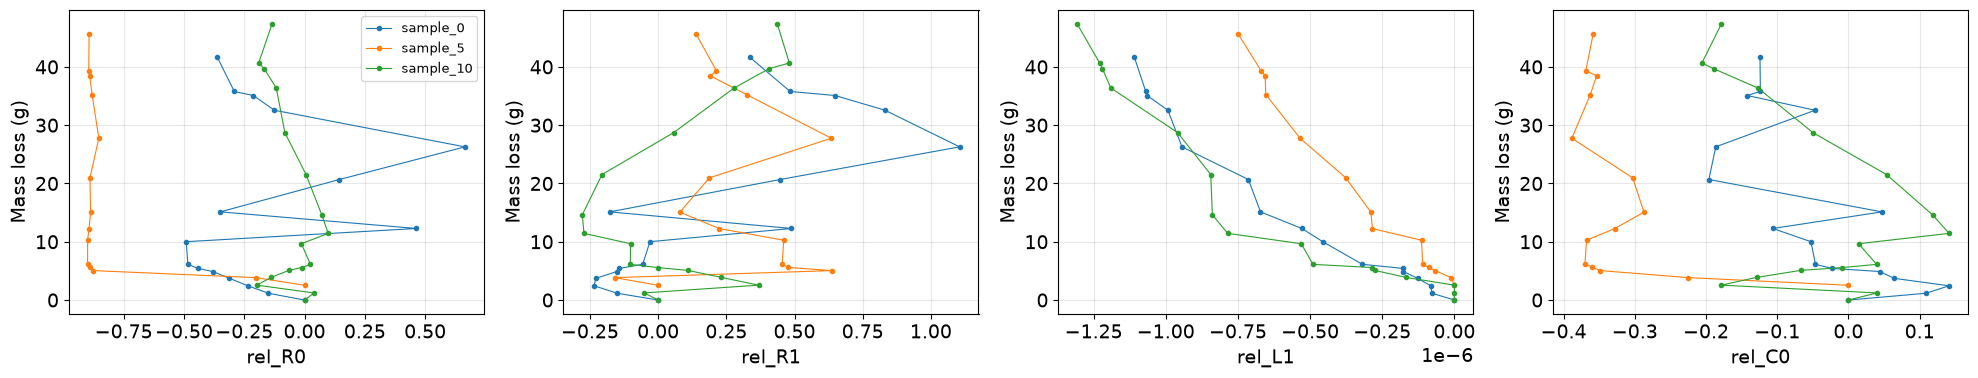

Leave-one-probe-out RMSE (g), linear baselines on real rows
                    sample_0  sample_5  sample_10   mean
model                                                   
train mean             13.90     14.93      15.68  14.84
calendar time only      2.30      2.06       2.73   2.37
rel_R0                 14.43     14.94      15.55  14.97
rel_R1                  9.87     16.10      13.91  13.30
rel_L1                  4.76     12.52       8.70   8.66
rel_C0                 11.89     24.18      14.63  16.90
all features            4.79      7.86       6.11   6.25


In [ ]:
# Do the features map to mass loss the same way across probes? Real rows only.
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline

real = merged_df_eng[~merged_df_eng['is_augmented']]

fig, axes = plt.subplots(1, len(FEATURE_COLS), figsize=(20, 4), dpi=100)
for ax, f in zip(axes, FEATURE_COLS):
    for s in ALL_SAMPLES:
        d = real[real['sample'] == s].sort_values('timestamp')
        ax.plot(d[f], d[TARGET_COL], marker='o', ms=3, lw=0.8, label=s)
    ax.set_xlabel(f); ax.set_ylabel('Mass loss (g)'); ax.grid(True, alpha=0.3)
axes[0].legend(fontsize=9)
plt.tight_layout(); plt.show()

# Leave-one-probe-out RMSE (g) of trivial models on real rows
# 'calendar time' is not a BVD feature; it is the reference every feature set has to beat.
rows = []
for name, feats in ([('train mean', None), ('calendar time only', ['time_days'])]
                    + [(f, [f]) for f in FEATURE_COLS] + [('all features', FEATURE_COLS)]):
    row = {'model': name}
    for s in ALL_SAMPLES:
        tr, va = real[real['sample'] != s], real[real['sample'] == s]
        if feats is None:
            pred = np.full(len(va), tr[TARGET_COL].mean())
        else:
            pred = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(
                tr[feats], tr[TARGET_COL]).predict(va[feats])
        row[s] = np.sqrt(np.mean((pred - va[TARGET_COL].values) ** 2))
    rows.append(row)
baseline_df = pd.DataFrame(rows).set_index('model')
baseline_df['mean'] = baseline_df.mean(axis=1)
print("Leave-one-probe-out RMSE (g), linear baselines on real rows")
print(baseline_df.round(2).to_string())


In [ ]:
# Ablation: one change at a time from TRAIN_CFG; RMSE (g) on real held-out rows, 5-seed ensemble (~5 min).
RUN_ABLATION = False
if RUN_ABLATION:
    S5 = SEEDS
    show('final config',                   TRAIN_CFG, S5)
    show('+ rel_C1 (5 features)',          {**TRAIN_CFG, 'feats': FEATURE_COLS + ['rel_C1']}, S5)
    show('- rel_L1 (R0,R1,C0,C1)',         {**TRAIN_CFG, 'feats': ['rel_R0', 'rel_R1', 'rel_C0', 'rel_C1']}, S5)
    show('- rel_L1 (R0,R1,C0)',            {**TRAIN_CFG, 'feats': ['rel_R0', 'rel_R1', 'rel_C0']}, S5)
    show('norm = group',                   {**TRAIN_CFG, 'norm': 'group'}, S5)
    show('noise 0',                        {**TRAIN_CFG, 'noise': 0.0}, S5)
    show('cubic spline interpolation',     {**TRAIN_CFG, 'interp': 'cubic'}, S5)
    show('window 3',                       {**TRAIN_CFG, 'window': 3}, S5)
    show('hampel k=3 spike filter',        {**TRAIN_CFG, 'hampel': 3}, S5)
    show('1000 epochs',                    {**TRAIN_CFG, 'epochs': 1000, 'eval_every': 10}, S5)


In [ ]:
# calculate number of parameters in model
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

n_params = count_parameters(model)
print(f"Model parameters: {n_params:,}")

Model parameters: 3,473



# 12. Raw arm: detailed evaluation (appendix)

The cells below use `fold_results`, which holds the raw-arm results. The BVD vs raw comparison
figures and tables are in the cells under section 11b and are saved to `Figures/BVD_vs_Raw`.


## ── Figure 1: Parity plots ────────────────────────────────────────

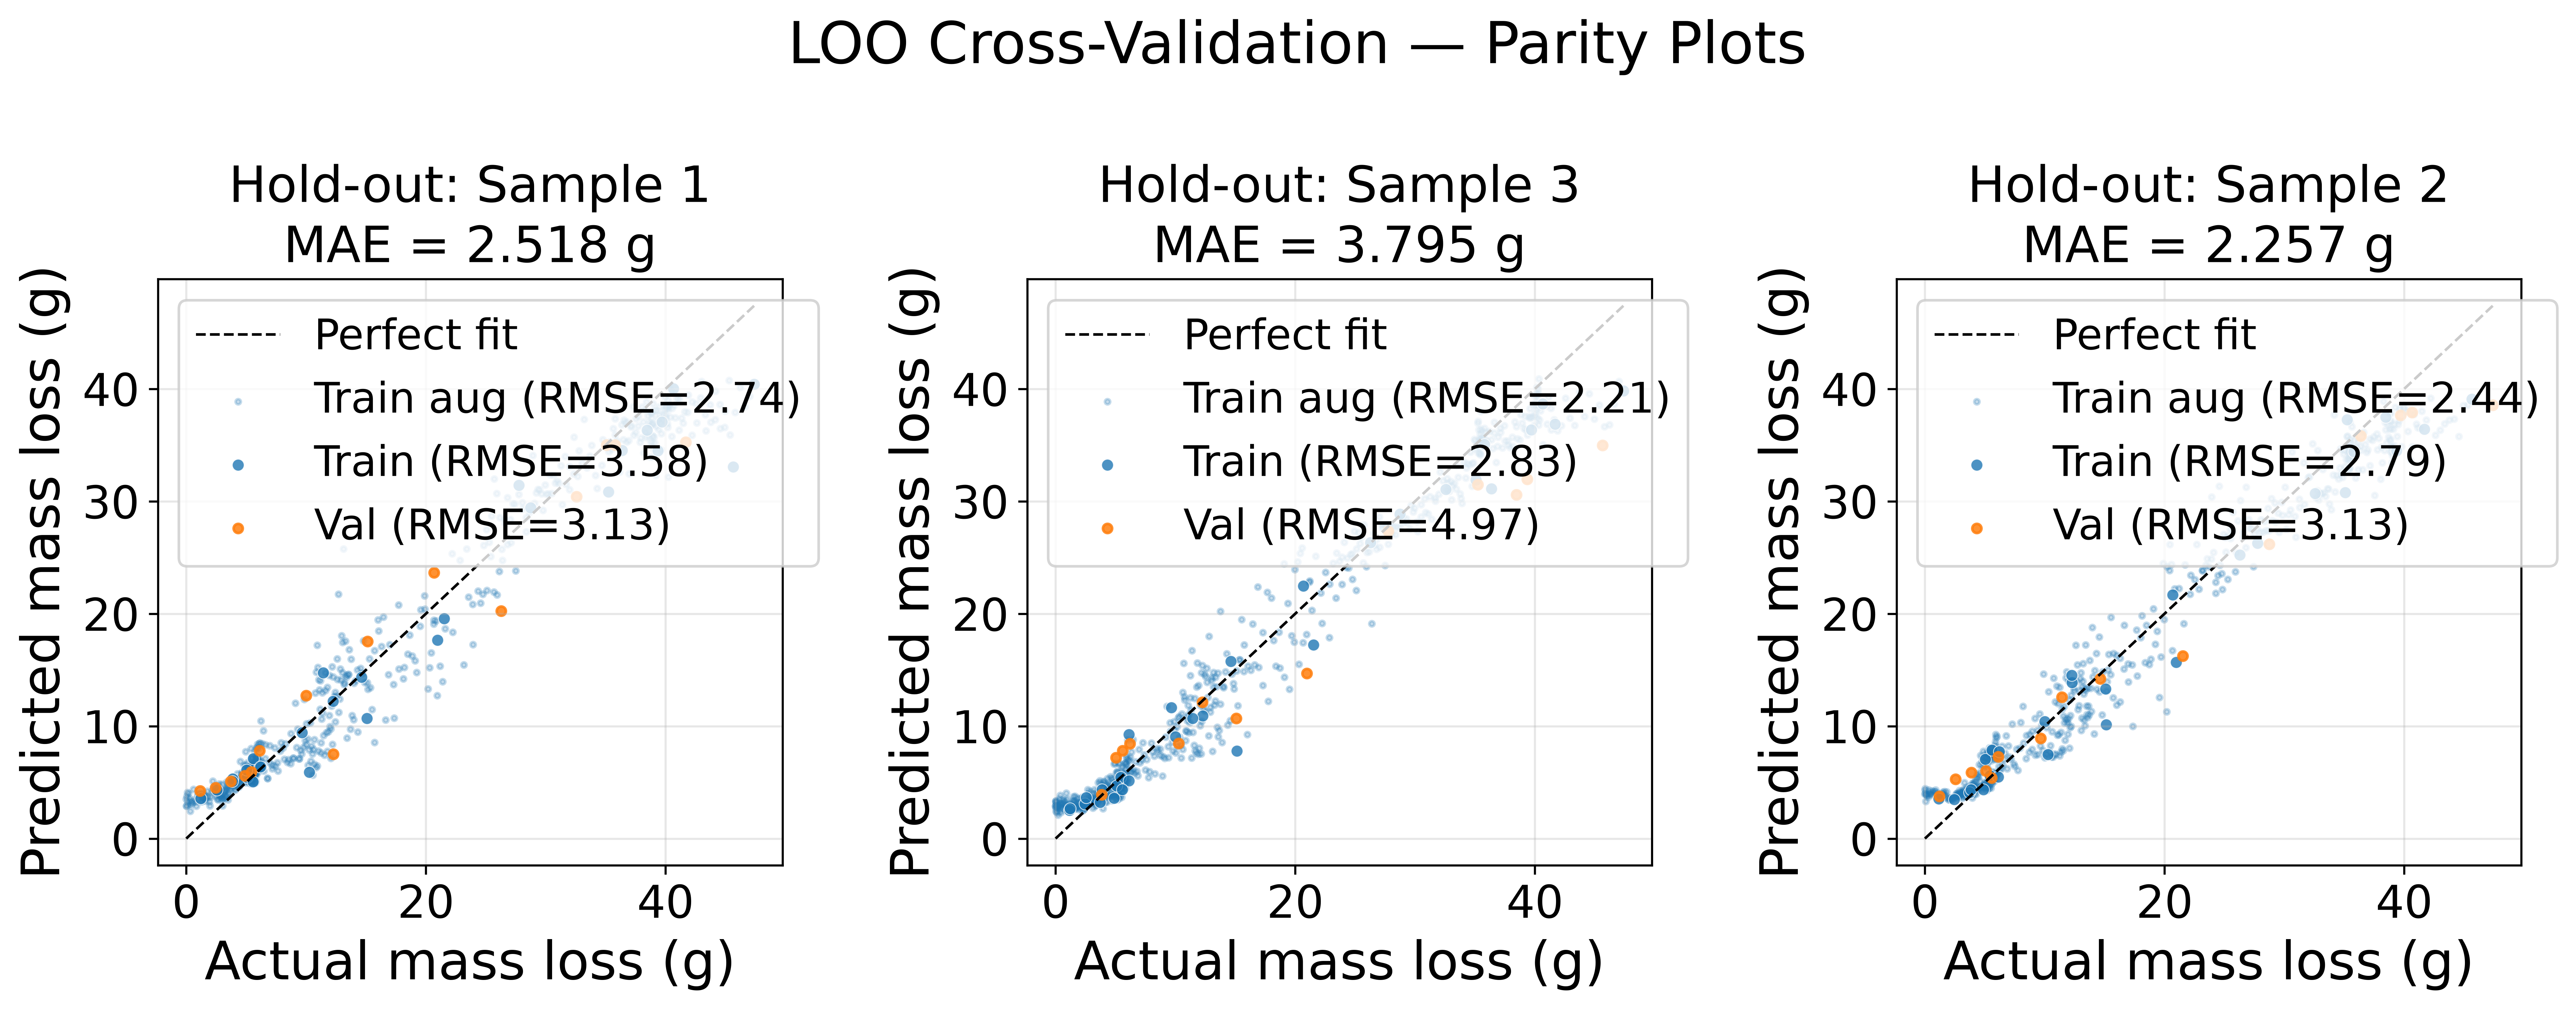


Hold-out sample         Tr RMSE  Tr RMSE(real)   Val RMSE   Val MAE   Val R²
---------------------------------------------------------------------------
  Sample 1               2.7430         3.5821     3.1330    2.5184   0.9463
  Sample 3               2.2143         2.8324     4.9659    3.7950   0.8824
  Sample 2               2.4447         2.7926     3.1275    2.2572   0.9594
---------------------------------------------------------------------------
  Average                                          3.7421    2.8569   0.9294


In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

font_scale = 4

plt.rcParams.update({
    'font.size': 14 + font_scale,
    'axes.labelsize': 16 + font_scale,
    'axes.titlesize': 15 + font_scale,
    'xtick.labelsize': 13 + font_scale,
    'ytick.labelsize': 13 + font_scale,
    'legend.fontsize': 12 + font_scale,
    'figure.titlesize': 18 + font_scale,
})

# Human-readable sample labels (adjust if your naming differs)
SAMPLE_LABEL = {
    'sample_0':  'Sample 1',
    'sample_5':  'Sample 3',
    'sample_10': 'Sample 2',
}

fig, axes = plt.subplots(1, 3, figsize=(14, 5.5))

for ax, r in zip(axes, fold_results):
    y_tr_true = r['y_train']
    y_vl_true = r['y_val']
    y_tr_pred = r['y_tr_pred']
    y_vl_pred = r['y_vl_pred']

    is_aug    = r.get('train_is_aug', np.zeros(len(y_tr_true), dtype=bool))
    is_real   = ~is_aug

    rmse_tr_all  = np.sqrt(mean_squared_error(y_tr_true, y_tr_pred))
    rmse_tr_real = np.sqrt(np.mean((y_tr_pred[is_real] - y_tr_true[is_real])**2)) \
                   if is_real.any() else float('nan')
    rmse_vl      = np.sqrt(mean_squared_error(y_vl_true, y_vl_pred))
    mae_vl       = mean_absolute_error(y_vl_true, y_vl_pred)

    y_all = np.concatenate([y_tr_true, y_vl_true, y_tr_pred, y_vl_pred])
    y_min, y_max = y_all.min(), y_all.max()

    ax.plot([y_min, y_max], [y_min, y_max], 'k--', lw=1, label='Perfect fit')
    if is_aug.any():
        ax.scatter(y_tr_true[is_aug], y_tr_pred[is_aug], s=4, alpha=0.25,
                   color='tab:blue', label=f'Train aug (RMSE={rmse_tr_all:.2f})')
    if is_real.any():
        ax.scatter(y_tr_true[is_real], y_tr_pred[is_real], s=20, alpha=0.8,
                   color='tab:blue', edgecolors='white', linewidths=0.3,
                   label=f'Train (RMSE={rmse_tr_real:.2f})')
    ax.scatter(y_vl_true, y_vl_pred, s=12, alpha=0.85, color='tab:orange',
               label=f'Val (RMSE={rmse_vl:.2f})')

    label = SAMPLE_LABEL.get(r['val_sample'], r['val_sample'])
    ax.set_title(f'Hold-out: {label}\nMAE = {mae_vl:.3f} g')
    ax.set_xlabel('Actual mass loss (g)')
    ax.set_ylabel('Predicted mass loss (g)')
    ax.legend(loc='upper left')
    ax.grid(True, alpha=0.3)

plt.suptitle('LOO Cross-Validation — Parity Plots')
plt.tight_layout()
plt.show()

# ── Summary table (with R²) ────────────────────────────────────────────────────
print(f"\n{'Hold-out sample':<20} {'Tr RMSE':>10} {'Tr RMSE(real)':>14} {'Val RMSE':>10} {'Val MAE':>9} {'Val R²':>8}")
print("-" * 75)
for r in fold_results:
    label     = SAMPLE_LABEL.get(r['val_sample'], r['val_sample'])
    is_real   = ~r.get('train_is_aug', np.zeros(len(r['y_train']), dtype=bool))
    rmse_tr   = np.sqrt(mean_squared_error(r['y_train'], r['y_tr_pred']))
    rmse_tr_r = np.sqrt(np.mean((r['y_tr_pred'][is_real] - r['y_train'][is_real])**2)) \
                if is_real.any() else float('nan')
    rmse_vl   = np.sqrt(mean_squared_error(r['y_val'], r['y_vl_pred']))
    r2_vl     = r2_score(r['y_val'], r['y_vl_pred'])
    print(f"  {label:<18} {rmse_tr:>10.4f} {rmse_tr_r:>14.4f} {rmse_vl:>10.4f} {r['mae']:>9.4f} {r2_vl:>8.4f}")
avg_mae     = np.mean([r['mae'] for r in fold_results])
avg_rmse_vl = np.mean([np.sqrt(mean_squared_error(r['y_val'], r['y_vl_pred'])) for r in fold_results])
avg_r2_vl   = np.mean([r2_score(r['y_val'], r['y_vl_pred']) for r in fold_results])
print("-" * 75)
print(f"  {'Average':<18} {'':>10} {'':>14} {avg_rmse_vl:>10.4f} {avg_mae:>9.4f} {avg_r2_vl:>8.4f}")

# ── Bootstrap over time points ─────────────────────────────────────────────────
N_BOOT = 1000
rng_boot = np.random.default_rng(0)

boot_stats = []   # one dict per fold

for r in fold_results:
    yt = r['y_val']
    yp = r['y_vl_pred']
    n  = len(yt)

    boot_rmse = np.empty(N_BOOT)
    boot_r2   = np.empty(N_BOOT)
    boot_mae  = np.empty(N_BOOT)

    for b in range(N_BOOT):
        idx = rng_boot.integers(0, n, size=n)
        boot_rmse[b] = np.sqrt(np.mean((yp[idx] - yt[idx])**2))
        boot_r2[b]   = r2_score(yt[idx], yp[idx])
        boot_mae[b]  = np.mean(np.abs(yp[idx] - yt[idx]))

    boot_stats.append({
        'label':     SAMPLE_LABEL.get(r['val_sample'], r['val_sample']),
        'rmse':      boot_rmse,
        'r2':        boot_r2,
        'mae':       boot_mae,
        'rmse_mean': boot_rmse.mean(),
        'rmse_std':  boot_rmse.std(),
        'rmse_ci95': np.percentile(boot_rmse, [2.5, 97.5]),
        'r2_mean':   boot_r2.mean(),
        'r2_std':    boot_r2.std(),
        'r2_ci95':   np.percentile(boot_r2, [2.5, 97.5]),
    })


## ── Figure 2: Bootstrap RMSE & R² distributions ───────────────────────────────

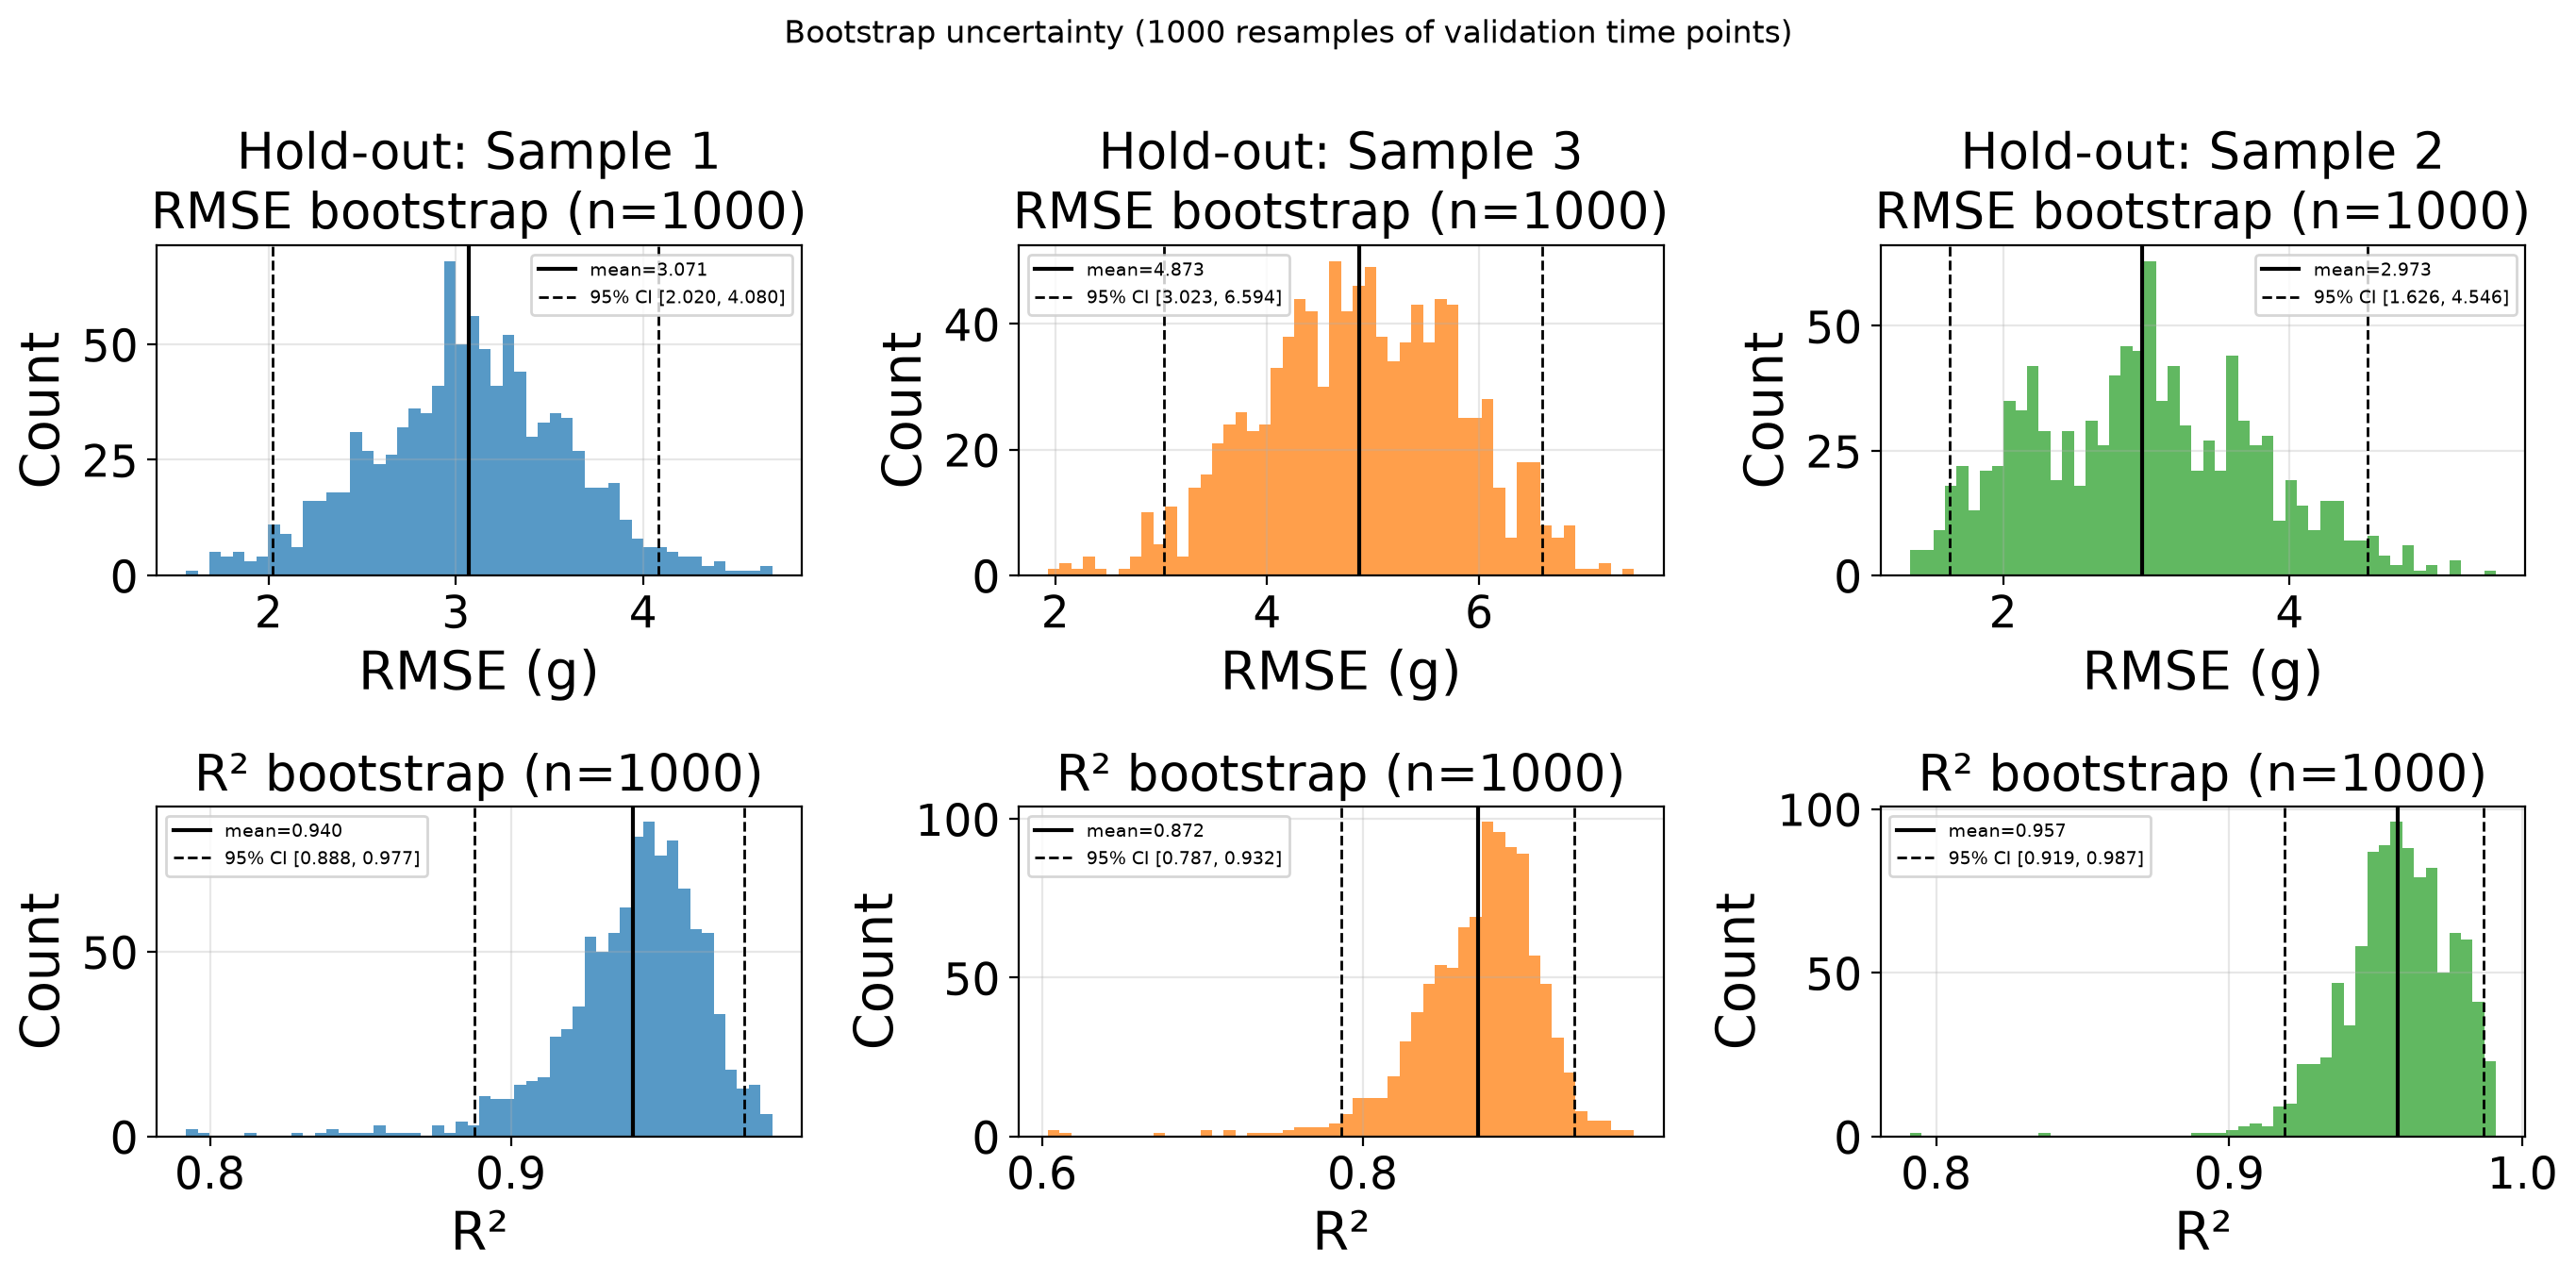

In [ ]:
fig2, axes2 = plt.subplots(2, 3, figsize=(14, 7), dpi=200)
colors_fold = ['tab:blue', 'tab:orange', 'tab:green']

for col, (bs, color) in enumerate(zip(boot_stats, colors_fold)):
    # Top row: RMSE distribution
    ax = axes2[0, col]
    ax.hist(bs['rmse'], bins=50, color=color, alpha=0.75, edgecolor='none')
    lo, hi = bs['rmse_ci95']
    ax.axvline(bs['rmse_mean'], color='k',      lw=1.5, label=f"mean={bs['rmse_mean']:.3f}")
    ax.axvline(lo,              color='k',      lw=1,   linestyle='--', label=f"95% CI [{lo:.3f}, {hi:.3f}]")
    ax.axvline(hi,              color='k',      lw=1,   linestyle='--')
    ax.set_title(f"Hold-out: {bs['label']}\nRMSE bootstrap (n={N_BOOT})")
    ax.set_xlabel('RMSE (g)')
    ax.set_ylabel('Count')
    ax.legend(fontsize=7)
    ax.grid(True, alpha=0.3)

    # Bottom row: R² distribution
    ax = axes2[1, col]
    ax.hist(bs['r2'], bins=50, color=color, alpha=0.75, edgecolor='none')
    lo2, hi2 = bs['r2_ci95']
    ax.axvline(bs['r2_mean'], color='k', lw=1.5, label=f"mean={bs['r2_mean']:.3f}")
    ax.axvline(lo2,           color='k', lw=1,   linestyle='--', label=f"95% CI [{lo2:.3f}, {hi2:.3f}]")
    ax.axvline(hi2,           color='k', lw=1,   linestyle='--')
    ax.set_title(f"R² bootstrap (n={N_BOOT})")
    ax.set_xlabel('R²')
    ax.set_ylabel('Count')
    ax.legend(fontsize=7)
    ax.grid(True, alpha=0.3)

plt.suptitle(f'Bootstrap uncertainty ({N_BOOT} resamples of validation time points)', fontsize=12)
plt.tight_layout()
plt.show()

## ── Figure 3: RMSE variance per fold (bar chart with CI error bars) ────────────

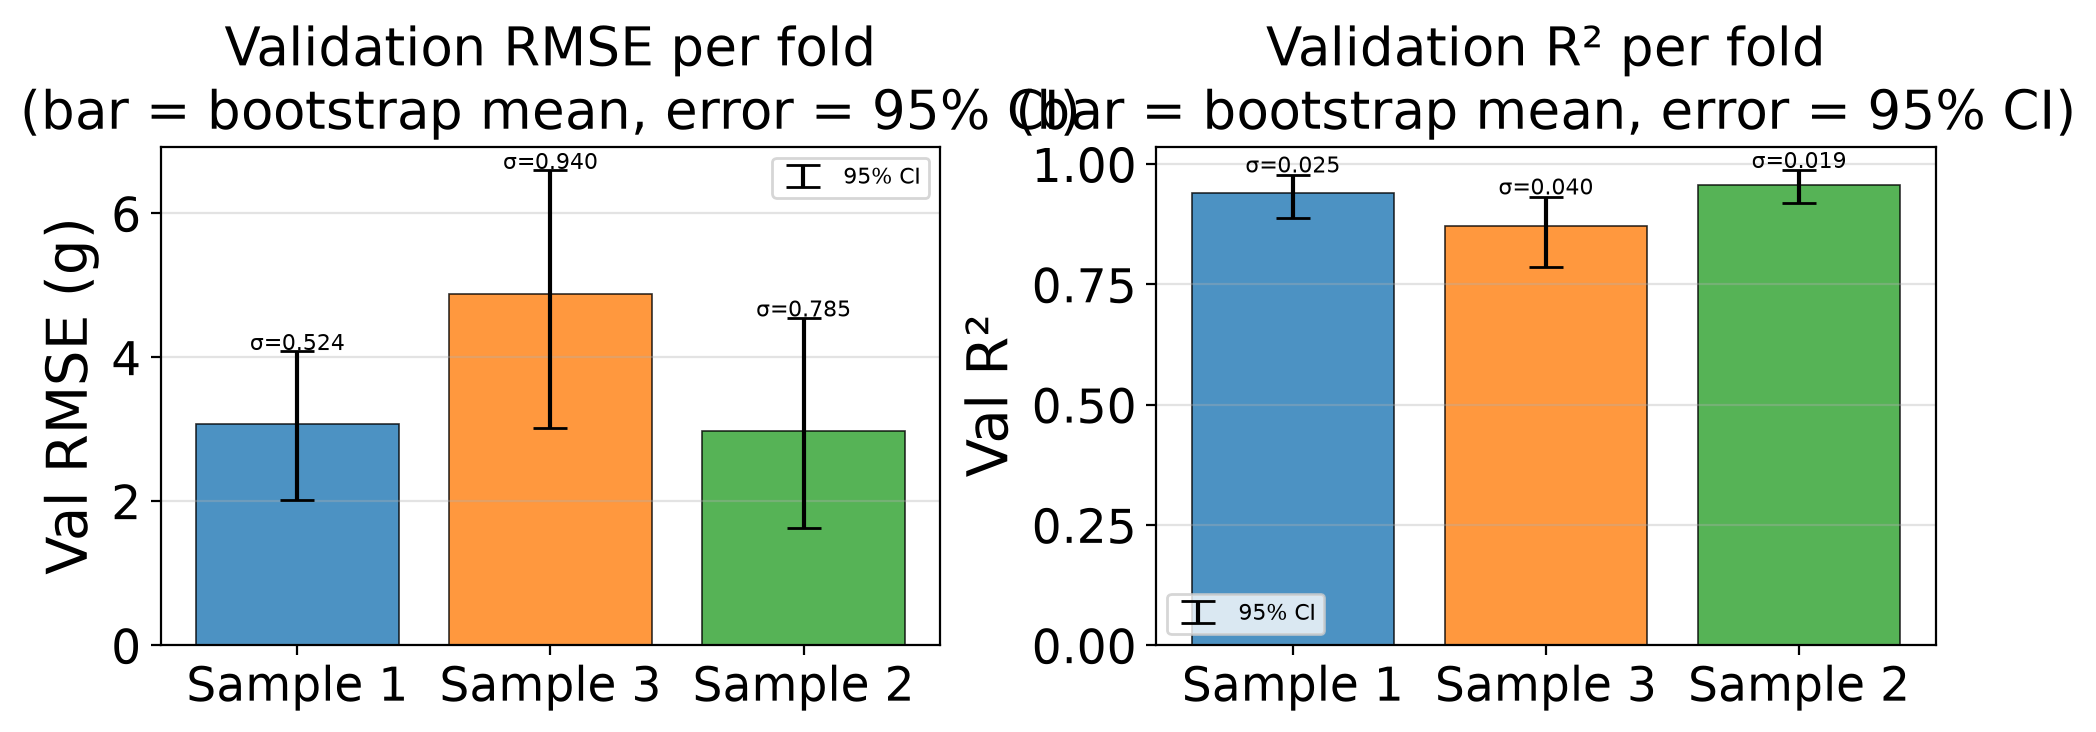


Hold-out         RMSE mean   RMSE std        RMSE 95% CI   R² mean   R² std         R² 95% CI
---------------------------------------------------------------------------------------------
  Sample 1          3.0712     0.5237   [2.0196, 4.0799]      0.9404   0.0245  [0.8877, 0.9774]
  Sample 3          4.8725     0.9402   [3.0226, 6.5945]      0.8721   0.0398  [0.7865, 0.9317]
  Sample 2          2.9730     0.7850   [1.6259, 4.5455]      0.9574   0.0188  [0.9190, 0.9867]


In [ ]:

labels_list  = [bs['label']    for bs in boot_stats]
rmse_means   = [bs['rmse_mean'] for bs in boot_stats]
rmse_stds    = [bs['rmse_std']  for bs in boot_stats]
rmse_ci_lo   = [bs['rmse_mean'] - bs['rmse_ci95'][0] for bs in boot_stats]
rmse_ci_hi   = [bs['rmse_ci95'][1] - bs['rmse_mean'] for bs in boot_stats]
r2_means     = [bs['r2_mean']  for bs in boot_stats]
r2_stds      = [bs['r2_std']   for bs in boot_stats]
r2_ci_lo     = [bs['r2_mean'] - bs['r2_ci95'][0] for bs in boot_stats]
r2_ci_hi     = [bs['r2_ci95'][1] - bs['r2_mean'] for bs in boot_stats]

x = np.arange(len(labels_list))

fig3, (ax_r, ax_r2) = plt.subplots(1, 2, figsize=(10, 4), dpi=200)

bars = ax_r.bar(x, rmse_means, color=colors_fold, alpha=0.8, edgecolor='k', linewidth=0.6)
ax_r.errorbar(x, rmse_means,
              yerr=[rmse_ci_lo, rmse_ci_hi],
              fmt='none', color='k', capsize=6, lw=1.5, label='95% CI')
ax_r.set_xticks(x); ax_r.set_xticklabels(labels_list)
ax_r.set_ylabel('Val RMSE (g)')
ax_r.set_title('Validation RMSE per fold\n(bar = bootstrap mean, error = 95% CI)')
ax_r.legend(fontsize=8)
ax_r.grid(True, axis='y', alpha=0.35)
# Annotate std
for xi, (mean, std) in enumerate(zip(rmse_means, rmse_stds)):
    ax_r.text(xi, mean + rmse_ci_hi[xi] + 0.02, f'σ={std:.3f}', ha='center', fontsize=8)

bars2 = ax_r2.bar(x, r2_means, color=colors_fold, alpha=0.8, edgecolor='k', linewidth=0.6)
ax_r2.errorbar(x, r2_means,
               yerr=[r2_ci_lo, r2_ci_hi],
               fmt='none', color='k', capsize=6, lw=1.5, label='95% CI')
ax_r2.set_xticks(x); ax_r2.set_xticklabels(labels_list)
ax_r2.set_ylabel('Val R²')
ax_r2.set_title('Validation R² per fold\n(bar = bootstrap mean, error = 95% CI)')
ax_r2.legend(fontsize=8)
ax_r2.grid(True, axis='y', alpha=0.35)
for xi, (mean, std) in enumerate(zip(r2_means, r2_stds)):
    ax_r2.text(xi, mean + r2_ci_hi[xi] + 0.005, f'σ={std:.3f}', ha='center', fontsize=8)

plt.tight_layout()
plt.show()

# ── Bootstrap summary table ────────────────────────────────────────────────────
print(f"\n{'Hold-out':<14} {'RMSE mean':>11} {'RMSE std':>10} {'RMSE 95% CI':>18} "
      f"{'R² mean':>9} {'R² std':>8} {'R² 95% CI':>17}")
print("-" * 93)
for bs in boot_stats:
    lo_r,  hi_r  = bs['rmse_ci95']
    lo_r2, hi_r2 = bs['r2_ci95']
    print(f"  {bs['label']:<12} {bs['rmse_mean']:>11.4f} {bs['rmse_std']:>10.4f} "
          f"  [{lo_r:.4f}, {hi_r:.4f}]   "
          f"{bs['r2_mean']:>9.4f} {bs['r2_std']:>8.4f}  [{lo_r2:.4f}, {hi_r2:.4f}]")